# Extended outage data + NOAA + NWS warnings (base) vs. + new grid data (proposed)

**Authors:** Kunatip Eiampan, Imtiaz Ahmad

**Problem statement:** *Can we predict how severe a major power outage will become, using historical outage data and recent storm information available when the outage starts?*

| | Data |
|---|---|
| **Experiment 1: base model** | extended outage data (`outage_extended.xlsx`, 2000–2024) + NOAA Storm Events + **NWS watches / warnings** |
| **Experiment 2: proposed model** | base + **new grid data** (EIA-861 reliability, smart meters, circuits; FERC Form 1 hardening; previous year) |

**Why NWS warnings?** NOAA Storm Events is compiled after the event (feedback W1). NWS watches and warnings are issued in real time; we use only each warning's issue time and the expiry time announced **at issue**, so they're exactly what a utility could see when the outage started.

**Train / test:** train 2000–2021, test 2022–2024.

| Target | Definition | Metrics |
|---|---|---|
| Customers affected | log(1 + customers per 100k population) | RMSE, R², MAE, Spearman |
| Outage duration | log(1 + minutes) | RMSE, R², MAE, Spearman |
| Severe or not | Level III (above the 75th percentile, from training rows) in customers **or** duration | confusion matrix, precision, recall, F1, ROC-AUC, PR-AUC, balanced accuracy |

**Scenarios**
- **A (pre-event):** only information known at outage start.
- **B (with cause):** A plus the reported cause.

**Storm-matching rules (NOAA):** R0 = the proposal rule, then overlap, strict and completed (section 3).

**Before running:** the project folder (one level up) must contain:
- `Data/outage_extended.xlsx` and the `StormEvents_details*.csv` files
- `Data/nws_raw/nws_events.parquet` (from `progress_stage2/download_nws_warnings.py`)
- `Data/pudl_raw/` and `Data/ext_raw/`

Outputs go to `progress_stage2/results_outage_extended_noaa_nws_newgrid/`.

## 0. Setup and imports

In [1]:
import io
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesClassifier, ExtraTreesRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, mean_squared_error

## 1. Configuration

Every setting in one place. Paths are relative to the folder this notebook is in.

In [2]:
# the notebook sits in progress_stage2/; the data is in the project folder one level up
ROOT = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "Data")) else os.path.dirname(os.getcwd())
DATA_DIR = os.path.join(ROOT, "Data")
RAW_EXT = os.path.join(DATA_DIR, "ext_raw")       # ONI, Census, BEA downloads
PUDL = os.path.join(DATA_DIR, "pudl_raw")         # EIA-861 / FERC Form 1 parquet files
OUT_DIR = os.path.join(ROOT, "progress_stage2", "results_outage_extended_noaa_nws_newgrid")  # CSV / PNG outputs
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
TEST_START = pd.Timestamp("2022-01-01")     # test period = 2022-2024
OUTAGE_FILE = "outage_extended.xlsx"        # Purdue 2000-2016 + DOE OE-417 2016-2024
NWS_FILE = os.path.join(DATA_DIR, "nws_raw", "nws_events.parquet")
NWS_START = pd.Timestamp("2006-01-01")      # all watch / warning types archived from 12 Nov 2005
FORM_2024 = pd.Timestamp("2024-01-01")      # OE-417 form revision
REGIME_YEAR = 2011                          # reporting changed around 2011

# targets
EXCLUDE_ZEROS = True        # 0 customers / 0 minutes = no interruption -> not a severity target

# storm matching
LOOKBACK_HOURS = 24                         # storm active within 24 h before the outage start
LOOKBACK = np.timedelta64(24, "h")
BUFFER = np.timedelta64(1, "h")             # strict rule: storm began >= 1 h before the start

# history features
SMOOTHING = 5.0                             # shrink small-sample means toward the prior

# models
HALF_LIFE_YEARS = 4.0                       # recency weight: 4 years older counts half
N_INNER = 4                                 # inner folds for threshold tuning / OOF predictions
COST_RATIOS = [1, 3, 5]                     # missed severe outage : false alarm

TASKS = {"customers_reg": ("reg", "log_customers"),
         "duration_reg": ("reg", "log_duration"),
         "is_severe": ("bin", None)}

## 2. Data loading

### 2.1 Outages

- `outage_extended.xlsx` has 4,279 reports: Purdue (2000 – Jul 2016) plus DOE OE-417 (Jul 2016 – 2024).
- Several reports of the same event (same start time and state) are merged into the most complete one.
- `N.STATES.AFFECTED` is missing for Purdue rows; those are single-state reports.

In [3]:
def merge_same_event(raw):
    """One row per (start, state): keep the report with the most information."""
    key = ["OUTAGE.START.DATE", "OUTAGE.START.TIME", "U.S._STATE"]
    info = raw["CUSTOMERS.AFFECTED"].notna().astype(int) + raw["OUTAGE.DURATION"].notna().astype(int)
    keep = (raw.assign(_info=info).sort_values("_info", ascending=False, kind="mergesort")
            .drop_duplicates(key).index)
    out = raw.loc[sorted(keep)].reset_index(drop=True)
    print(f"Merged reports of the same event: {len(raw)} -> {len(out)} rows")
    return out

### 2.2 NOAA Storm Events

- One CSV per year, 2000–2024.
- Event types are grouped into families (wind, winter, cold, tropical, tornado, flood, hail, heat, lightning, fire, other).
- Droughts are removed: they last months and are listed once per zone.
- Events are stored per state, sorted by begin time, so matching is fast.

In [4]:
NOAA_COLS = ['STATE', 'BEGIN_DATE_TIME', 'END_DATE_TIME', 'EVENT_TYPE', 'MAGNITUDE', 'CZ_TYPE', 'CZ_FIPS']


def read_csv_safely(path, **kwargs):
    """Read a NOAA CSV that may contain null bytes or mixed line endings."""
    with open(path, "rb") as fh:
        raw = fh.read().replace(b"\x00", b"")
    text = raw.decode("latin1", errors="replace").replace("\r\n", "\n").replace("\r", "\n")
    return pd.read_csv(io.StringIO(text), **kwargs)


def load_noaa(data_dir=DATA_DIR):
    files = sorted(os.path.join(data_dir, f) for f in os.listdir(data_dir)
                   if re.search(r"StormEvents", f))
    noaa_df = pd.concat(
        [read_csv_safely(f, on_bad_lines="skip", low_memory=False, dtype=str,
                         usecols=lambda c: c in NOAA_COLS) for f in files],
        ignore_index=True)
    print(f"NOAA data: {len(noaa_df)} rows from {len(files)} files")
    return noaa_df

In [5]:
EVENT_FAMILY = {
    'Thunderstorm Wind': 'wind',
    'High Wind': 'wind',
    'Strong Wind': 'wind',
    'Marine Thunderstorm Wind': 'wind',
    'Marine High Wind': 'wind',
    'Marine Strong Wind': 'wind',
    'Winter Storm': 'winter',
    'Heavy Snow': 'winter',
    'Ice Storm': 'winter',
    'Blizzard': 'winter',
    'Winter Weather': 'winter',
    'Lake-Effect Snow': 'winter',
    'Sleet': 'winter',
    'Freezing Fog': 'winter',
    'Frost/Freeze': 'cold',
    'Extreme Cold/Wind Chill': 'cold',
    'Cold/Wind Chill': 'cold',
    'Hurricane (Typhoon)': 'tropical',
    'Hurricane': 'tropical',
    'Tropical Storm': 'tropical',
    'Tropical Depression': 'tropical',
    'Storm Surge/Tide': 'tropical',
    'Marine Hurricane/Typhoon': 'tropical',
    'Marine Tropical Storm': 'tropical',
    'Tornado': 'tornado',
    'Waterspout': 'tornado',
    'Funnel Cloud': 'tornado',
    'Flash Flood': 'flood',
    'Flood': 'flood',
    'Coastal Flood': 'flood',
    'Lakeshore Flood': 'flood',
    'Heavy Rain': 'flood',
    'Hail': 'hail',
    'Marine Hail': 'hail',
    'Heat': 'heat',
    'Excessive Heat': 'heat',
    'Lightning': 'lightning',
    'Marine Lightning': 'lightning',
    'Wildfire': 'fire',
}
FAMILIES = ['wind', 'winter', 'cold', 'tropical', 'tornado', 'flood', 'hail', 'heat', 'lightning', 'fire', 'other']
ONGOING_FAMILIES = ['wind', 'winter', 'tropical', 'flood']


def parse_noaa_time(s):
    out = pd.to_datetime(s, format="%d-%b-%y %H:%M:%S", errors="coerce")
    if out.isna().mean() > 0.5:                     # other export format
        out = pd.to_datetime(s, errors="coerce")
    if getattr(out.dt, "tz", None) is not None:
        out = out.dt.tz_localize(None)
    return out


def prepare_noaa(noaa_df):
    """Clean NOAA once; return per-state arrays sorted by storm begin time."""
    n = noaa_df[[c for c in NOAA_COLS if c in noaa_df.columns]].copy()
    n["CLEAN_STATE"] = n["STATE"].astype(str).str.upper().str.strip()
    n["BEGIN_DATE_TIME"] = parse_noaa_time(n["BEGIN_DATE_TIME"])
    n["END_DATE_TIME"] = parse_noaa_time(n["END_DATE_TIME"])
    n = n.dropna(subset=["BEGIN_DATE_TIME", "END_DATE_TIME", "CLEAN_STATE"])
    n = n[n["EVENT_TYPE"] != "Drought"].copy()      # months long, per-zone duplicated
    n["MAGNITUDE"] = pd.to_numeric(n["MAGNITUDE"], errors="coerce")
    n["FAMILY"] = n["EVENT_TYPE"].map(EVENT_FAMILY).fillna("other")
    n["ZONE"] = (n["CZ_TYPE"].astype(str) + "_" + n["CZ_FIPS"].astype(str)
                 if {"CZ_TYPE", "CZ_FIPS"}.issubset(n.columns) else "NA")

    by_state = {}
    for state, g in n.sort_values("BEGIN_DATE_TIME").groupby("CLEAN_STATE"):
        by_state[state] = {
            "begin": g["BEGIN_DATE_TIME"].values.astype("datetime64[ns]"),
            "end": g["END_DATE_TIME"].values.astype("datetime64[ns]"),
            "mag": g["MAGNITUDE"].values.astype(float),
            "event": g["EVENT_TYPE"].astype(str).values,
            "family": g["FAMILY"].astype(str).values,
            "zone": g["ZONE"].astype(str).values,
        }
    return by_state

In [6]:
def load_raw():
    raw = pd.read_excel(os.path.join(DATA_DIR, OUTAGE_FILE))
    raw = merge_same_event(raw)
    if "N.STATES.AFFECTED" in raw.columns:          # only in the extended file
        raw["N.STATES.AFFECTED"] = raw["N.STATES.AFFECTED"].fillna(1)
    noaa = prepare_noaa(load_noaa(DATA_DIR))
    for a in noaa.values():                 # longest storm per state -> overlap search bound
        a["maxdur"] = (a["end"] - a["begin"]).max()
    return raw, noaa

### 2.3 NWS watches, warnings and advisories (Iowa Environmental Mesonet)

The National Weather Service issues **watches** (A: conditions favour the hazard), **warnings** (W: hazard happening or imminent) and **advisories** (Y: less severe) for storms, floods, winter weather, heat and more. Source: the IEM archive of every VTEC event, downloaded per state and year by `download_nws_warnings.py`.

**Only real-time information is used:**
- `issue`: when the product was issued;
- `init_expire`: the expiry time announced **at issue**. The final expiry, which can be extended later, is not used.

Times are converted from UTC to the state's main time zone (DST-aware; states spanning two zones use the larger one, so up to 1 h off at the edges).

**Features at outage start** (same state):

| Feature | Meaning |
|---|---|
| `nws_warn_active`, `nws_watch_active`, `nws_adv_active` | warnings / watches / advisories in effect at outage start |
| `nws_warn_active_<family>` | warnings in effect, by family (wind, tornado, winter, tropical, flood, heat, cold, fire, other) |
| `nws_warn_24h`, `nws_warn_7d` | warnings issued in the last 24 h / 7 days |
| `nws_hours_since_warning` | hours since the last warning was issued (capped at 168) |

**Coverage:** all product types are archived only from 12 Nov 2005, so outages **before 2006 get missing values** (filled by the model's imputer, with a "was missing" indicator).

In [7]:
NWS_FAMILY = {"SV": "wind", "HW": "wind", "WI": "wind", "EW": "wind", "LW": "wind", "GL": "wind", "SR": "wind",
              "TO": "tornado",
              "WS": "winter", "BZ": "winter", "IS": "winter", "WW": "winter", "LE": "winter", "ZR": "winter",
              "SN": "winter", "HS": "winter", "SQ": "winter", "LB": "winter", "SB": "winter",
              "HU": "tropical", "TR": "tropical", "TY": "tropical", "SS": "tropical", "HI": "tropical", "TI": "tropical",
              "FF": "flood", "FA": "flood", "FL": "flood", "CF": "flood", "LS": "flood", "HY": "flood",
              "EH": "heat", "HT": "heat", "XH": "heat",
              "EC": "cold", "WC": "cold", "FZ": "cold", "HZ": "cold", "FR": "cold", "CW": "cold", "XC": "cold",
              "FW": "fire"}
NWS_FAMILIES = ["wind", "tornado", "winter", "tropical", "flood", "heat", "cold", "fire", "other"]
NWS_NUM = (["nws_warn_active", "nws_watch_active", "nws_adv_active"]
           + [f"nws_warn_active_{f}" for f in NWS_FAMILIES]
           + ["nws_warn_24h", "nws_warn_7d", "nws_hours_since_warning"])
STATE_TZ = {**{s: "America/New_York" for s in ["CT", "DE", "DC", "FL", "GA", "IN", "KY", "ME", "MD", "MA", "MI",
                                               "NH", "NJ", "NY", "NC", "OH", "PA", "RI", "SC", "VT", "VA", "WV"]},
            **{s: "America/Chicago" for s in ["AL", "AR", "IL", "IA", "KS", "LA", "MN", "MS", "MO", "NE", "ND",
                                              "OK", "SD", "TN", "TX", "WI"]},
            **{s: "America/Denver" for s in ["CO", "ID", "MT", "NM", "UT", "WY"]},
            "AZ": "America/Phoenix",
            **{s: "America/Los_Angeles" for s in ["CA", "NV", "OR", "WA"]},
            "AK": "America/Anchorage", "HI": "Pacific/Honolulu", "PR": "America/Puerto_Rico"}


def load_nws(path=NWS_FILE):
    """Watches (A), warnings (W), advisories (Y) per state, local time, sorted by issue time."""
    ev = pd.read_parquet(path)
    ev = ev[ev["significance"].isin(["W", "A", "Y"]) & ev["state"].isin(STATE_TZ)].copy()
    ev["family"] = ev["phenomena"].map(NWS_FAMILY).fillna("other")
    by_state = {}
    for st, g in ev.groupby("state"):
        tz = STATE_TZ[st]
        issue = pd.to_datetime(g["issue"], utc=True, errors="coerce").dt.tz_convert(tz).dt.tz_localize(None)
        expire = pd.to_datetime(g["init_expire"], utc=True, errors="coerce").dt.tz_convert(tz).dt.tz_localize(None)
        g = g.assign(issue_local=issue, expire_local=expire.fillna(issue)).dropna(subset=["issue_local"])
        g = g.sort_values("issue_local")
        by_state[st] = {"issue": g["issue_local"].values.astype("datetime64[ns]"),
                        "expire": g["expire_local"].values.astype("datetime64[ns]"),
                        "sig": g["significance"].values, "family": g["family"].values}
    print(f"NWS products: {len(ev)} (watches, warnings, advisories) in {len(by_state)} states")
    return by_state


def nws_features(df, nws_by_state):
    """Real-time warning features at each outage start (NaN before NWS_START)."""
    h = np.timedelta64(1, "h")
    rows = []
    for st, t in zip(df["postal_code"].values, df["outage_start"].values.astype("datetime64[ns]")):
        a = nws_by_state.get(st)
        if a is None or np.isnat(t) or t < np.datetime64(NWS_START):
            rows.append({c: np.nan for c in NWS_NUM})
            continue
        hi = np.searchsorted(a["issue"], t, side="right")                  # issued before the start
        lo30 = np.searchsorted(a["issue"], t - np.timedelta64(30, "D"))
        idx = np.arange(lo30, hi)
        act = idx[a["expire"][idx] > t]                                    # in effect at the start
        sig, fam = a["sig"][act], a["family"][act]
        warn = idx[a["sig"][idx] == "W"]
        r = {"nws_warn_active": int((sig == "W").sum()), "nws_watch_active": int((sig == "A").sum()),
             "nws_adv_active": int((sig == "Y").sum())}
        for f in NWS_FAMILIES:
            r[f"nws_warn_active_{f}"] = int(((sig == "W") & (fam == f)).sum())
        r["nws_warn_24h"] = int((a["issue"][warn] >= t - 24 * h).sum())
        r["nws_warn_7d"] = int((a["issue"][warn] >= t - 168 * h).sum())
        r["nws_hours_since_warning"] = (float(min((t - a["issue"][warn].max()) / h, 168.0))
                                        if warn.size else 168.0)
        rows.append(r)
    return pd.DataFrame(rows, index=df.index)


nws_by_state = load_nws()

NWS products: 1352918 (watches, warnings, advisories) in 52 states


## 3. Storm matching (NOAA → outage)

Each outage is matched to storm events in the **same state**. Four rules are compared:

| Rule | Storm events used |
|---|---|
| `original` (R0, proposal rule) | **began within the 24 h** before the outage (start − 24 h ≤ begin ≤ start). A storm that began earlier is ignored even if still active: the problem raised in W2 |
| `overlap` | began ≤ start, ended ≥ start − 24 h, with **no 14-day cut-off** (fixes long-running storms) |
| `strict` | as overlap, but must have **begun ≥ 1 h before the start**; magnitudes only from storms already ended (**operational rule**) |
| `completed` | only storms that **ended before the start** (most conservative) |

**Features:** counts in the last 24 h and 7 days, number of zones and event types, counts per family, storm still active at start, hours since the last storm, maximum wind and hail of completed storms, and the most common event type. Damage, injury and death columns are never used.

In [8]:
def empty_storm_row(lookback_hours):
    """Feature values for an outage with no matching storm."""
    row = {
        "noaa_storm_count": 0, "noaa_count_7d": 0, "noaa_n_zones": 0,
        "noaa_n_types": 0, "noaa_n_ongoing": 0, "noaa_has_ongoing_storm": 0,
        "noaa_has_storm": 0, "hours_since_last_storm": float(lookback_hours),
        "noaa_max_wind_kt": np.nan, "noaa_max_hail_in": np.nan,
        "noaa_dominant_event_type": "None",
    }
    row.update({f"noaa_cnt_{f}": 0 for f in FAMILIES})
    row.update({f"noaa_ongoing_{f}": 0 for f in ONGOING_FAMILIES})
    return row


def storm_features_for_outage(a, start, lookback_hours):
    """
    PROPOSAL rule (R0): storms in the same state that BEGAN within the look-back window
    (outage start - LOOKBACK_HOURS <= BEGIN <= outage start). Long-running storms that began
    earlier are not counted (feedback W2).  Magnitudes use completed storms only
    (an ongoing storm's recorded peak may come after the outage began).
    """
    row = empty_storm_row(lookback_hours)
    lb = np.timedelta64(int(lookback_hours), "h")

    hi = np.searchsorted(a["begin"], start, side="right")
    row["noaa_count_7d"] = int(hi - np.searchsorted(a["begin"], start - np.timedelta64(7, "D")))
    lo = np.searchsorted(a["begin"], start - lb)   # proposal rule: storm BEGAN within the window
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= start - lb]
    if idx.size == 0:
        return row

    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > start

    row["noaa_storm_count"] = int(idx.size)
    row["noaa_has_storm"] = 1
    row["noaa_n_zones"] = int(np.unique(zone).size)
    row["noaa_n_types"] = int(np.unique(ev).size)
    row["noaa_n_ongoing"] = int(ongoing.sum())
    row["noaa_has_ongoing_storm"] = int(ongoing.any())
    row["hours_since_last_storm"] = (0.0 if ongoing.any() else
                                     float((start - end.max()) / np.timedelta64(1, "h")))
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row

In [9]:
def storm_row(a, t, mode):
    """
    mode "original"  : v5 rule (storm began <= start and <= 14 days + 24 h before it)
    mode "overlap"   : any storm with begin <= start and end >= start - 24 h       (W2)
    mode "strict"    : overlap, but the storm must have begun >= 1 h before start (W1);
                       'ongoing' = not ended by the start (observable then); magnitudes
                       only from storms that had already ended
    mode "completed" : only storms that ended before the start (most conservative)
    """
    if mode == "original":
        return storm_features_for_outage(a, t, 24)
    row = empty_storm_row(24)
    t_known = t - BUFFER if mode in ("strict", "completed") else t
    hi = np.searchsorted(a["begin"], t_known, side="right")
    row["noaa_count_7d"] = int(hi - np.searchsorted(a["begin"], t_known - np.timedelta64(7, "D")))
    lo = np.searchsorted(a["begin"], t - LOOKBACK - a["maxdur"])
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= t - LOOKBACK]
    if mode == "completed":
        idx = idx[a["end"][idx] <= t]
    if idx.size == 0:
        return row
    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > t
    row.update(noaa_storm_count=int(idx.size), noaa_has_storm=1,
               noaa_n_zones=int(np.unique(zone).size), noaa_n_types=int(np.unique(ev).size),
               noaa_n_ongoing=int(ongoing.sum()), noaa_has_ongoing_storm=int(ongoing.any()),
               hours_since_last_storm=(0.0 if ongoing.any() else
                                       float((t - end.max()) / np.timedelta64(1, "h"))))
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row


def storm_features(df, noaa, mode):
    rows = []
    for st, t in zip(df["clean_state"].values, df["outage_start"].values.astype("datetime64[ns]")):
        a = noaa.get(st)
        rows.append(empty_storm_row(24) if a is None or np.isnat(t) else storm_row(a, t, mode))
    return pd.DataFrame(rows, index=df.index)

## 4. Preprocessing

### 4.1 Feature lists and leakage guard

`LEAKAGE_COLS` lists columns that must **never** be model inputs: the targets themselves and information that only exists after the outage.

In [10]:
STATIC_NUM = ['anomaly_level', 'res_price', 'com_price', 'ind_price', 'total_price', 'res_sales', 'com_sales', 'ind_sales', 'total_sales', 'res_percen', 'com_percen', 'ind_percen', 'res_customers', 'com_customers', 'ind_customers', 'total_customers', 'res_cust_pct', 'com_cust_pct', 'ind_cust_pct', 'pc_realgsp_state', 'pc_realgsp_usa', 'pc_realgsp_rel', 'pc_realgsp_change', 'util_realgsp', 'total_realgsp', 'util_contri', 'pi_util_ofusa', 'population', 'poppct_urban', 'poppct_uc', 'popden_urban', 'popden_uc', 'popden_rural', 'areapct_urban', 'areapct_uc', 'pct_land', 'pct_water_tot', 'pct_water_inland']
SKEWED = ['res_sales', 'com_sales', 'ind_sales', 'total_sales', 'res_customers', 'com_customers', 'ind_customers', 'total_customers', 'util_realgsp', 'total_realgsp', 'population', 'popden_urban', 'popden_uc', 'popden_rural']
TIME_NUM = ['start_month', 'start_hour', 'is_weekend', 'post_regime', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']
NOAA_NUM = (["noaa_storm_count", "noaa_count_7d", "noaa_n_zones", "noaa_n_types",
             "noaa_n_ongoing", "noaa_has_ongoing_storm", "noaa_has_storm",
             "hours_since_last_storm", "noaa_max_wind_kt", "noaa_max_hail_in"]
            + [f"noaa_cnt_{f}" for f in FAMILIES]
            + [f"noaa_ongoing_{f}" for f in ONGOING_FAMILIES])
HIST_NUM = ['hist_state_n', 'hist_state_n_365d', 'hist_state_cust', 'hist_state_dur', 'hist_state_zero_rate', 'hist_global_cust', 'hist_global_dur']
RECENT_HIST = ['hist_global_cust_365d', 'hist_global_dur_365d', 'hist_state_cust_3y', 'hist_state_dur_3y', 'hist_state_n_30d', 'hist_global_n_365d']
STORM_TE = ['hist_storm_cust', 'hist_storm_dur', 'hist_state_storm_cust', 'hist_state_storm_dur']
CAUSE_TE = ['hist_cause_cust', 'hist_cause_dur', 'hist_state_cause_cust', 'hist_state_cause_dur']
AREA_NUM = ['area_hist_n', 'area_hist_n_365d', 'area_hist_log_cust', 'area_hist_log_dur', 'area_hist_attack_share', 'n_states_affected']
BASE_CAT = ['nerc_region', 'climate_region', 'climate_category', 'clean_state', 'noaa_dominant_event_type']
CAUSE_CAT = ['cause_reported']
CAUSE_NUM = ['is_named_hurricane']
GRID_NUM = []   # HIFLD state-level grid features: not used (no effect in v6)

# never allowed as model inputs (targets or post-event information)
LEAKAGE_COLS = ['cause_category', 'cause_category_detail', 'cust_reported_zero', 'customers_affected', 'demand_loss_mw', 'hurricane_names', 'log_customers', 'log_duration', 'obs', 'outage_duration', 'outage_restoration', 'outage_restoration_date', 'outage_restoration_time', 'start_year', 'year']
EXTRA_LEAKAGE = ['alert_criteria', 'area_affected', 'area_key', 'event_type_raw', 'same_start_reports', 'source']
LEAKAGE_COLS, EXTRA_LEAKAGE = set(LEAKAGE_COLS), set(EXTRA_LEAKAGE)

ECON_EIA = ['res_price', 'com_price', 'ind_price', 'total_price', 'res_sales', 'com_sales', 'ind_sales', 'total_sales', 'res_percen', 'com_percen', 'ind_percen', 'res_customers', 'com_customers', 'ind_customers', 'total_customers', 'res_cust_pct', 'com_cust_pct', 'ind_cust_pct']
ECON_BEA = ['pc_realgsp_state', 'pc_realgsp_usa', 'pc_realgsp_rel', 'pc_realgsp_change', 'util_realgsp', 'total_realgsp', 'util_contri', 'pi_util_ofusa']

### 4.2 Targets and time features

- Start and restoration timestamps are built from the date and time columns.
- Customers are normalised per 100,000 state population. Both targets are log-transformed.
- Rows are sorted by start time, because every split is chronological.
- Time features: month, hour, weekend, cyclic month/hour, and a reporting-regime flag (2011).

In [11]:
def combine_date_time(date_col, time_col):
    out = pd.to_datetime(date_col.astype(str) + " " + time_col.astype(str), errors="coerce")
    alt = (pd.to_datetime(date_col, errors="coerce").dt.normalize()
           + pd.to_timedelta(time_col.astype(str), errors="coerce"))
    return out.fillna(alt)


def create_targets(outage_df, exclude_zeros=EXCLUDE_ZEROS):
    """Timestamps + log targets; keep rows with a start time and >= 1 target."""
    df = outage_df.copy()
    df["OUTAGE_START"] = combine_date_time(df["OUTAGE.START.DATE"], df["OUTAGE.START.TIME"])
    df["OUTAGE_RESTORATION"] = combine_date_time(df["OUTAGE.RESTORATION.DATE"],
                                                 df["OUTAGE.RESTORATION.TIME"])
    df["CLEAN_STATE"] = df["U.S._STATE"].astype(str).str.upper().str.strip()

    cust = pd.to_numeric(df["CUSTOMERS.AFFECTED"], errors="coerce").clip(lower=0)
    dur = pd.to_numeric(df["OUTAGE.DURATION"], errors="coerce").clip(lower=0)
    pop = pd.to_numeric(df["POPULATION"], errors="coerce")
    df["cust_reported_zero"] = (cust == 0).astype(float).where(cust.notna())
    if exclude_zeros:
        cust, dur = cust.mask(cust == 0), dur.mask(dur == 0)
    df["log_customers"] = np.log1p(cust / (pop / 100_000))   # per 100k population
    df["log_duration"] = np.log1p(dur)

    keep = (df["log_customers"].notna() | df["log_duration"].notna()) & df["OUTAGE_START"].notna()
    print(f"Rows kept: {keep.sum()} / {len(df)} (need a start time and >= 1 target)")
    # sort by time: every split / CV fold below is chronological
    return (df[keep].sort_values("OUTAGE_START", kind="mergesort")
            .reset_index(drop=True))


def add_time_features(df):
    st = df["OUTAGE_START"]
    df["start_month"] = st.dt.month
    df["start_hour"] = st.dt.hour
    df["start_year"] = st.dt.year                # reporting only, NOT a feature
    df["is_weekend"] = st.dt.dayofweek.isin([5, 6]).astype(int)
    df["post_regime"] = (st.dt.year >= REGIME_YEAR).astype(int)
    df["month_sin"] = np.sin(2 * np.pi * df["start_month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["start_month"] / 12)
    df["hour_sin"] = np.sin(2 * np.pi * df["start_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["start_hour"] / 24)
    return df

### 4.3 Outage-history features (known at outage start)

These use only **earlier outages already restored** before this one started; if the restoration time is unknown, the outage counts as known 7 days after its start. Small samples are shrunk toward a broader average.

| Group | Features |
|---|---|
| State history | number of past outages (all time and last 365 days), mean customers / duration, share of zero-customer reports |
| Recent history | 365-day global means, 3-year state means, outages in the last 30 days |
| Storm-status history | past outcomes of outages with the same storm / no-storm status (globally, then in the state) |
| Cause history (scenario B) | past outcomes for the same reported cause, globally and in the state |
| Area history (`area_hist_*`) | state + county history, precomputed in `outage_extended.xlsx` |

In [12]:
def add_history_features(df, k=SMOOTHING):
    """
    Summarise EARLIER outages in the same state whose outcome was already
    known (restored before this outage started; if restoration is missing,
    known 7 days after start). The current outage's own target is never used.
    """
    start = df["OUTAGE_START"].values.astype("datetime64[ns]")
    known_at = df["OUTAGE_RESTORATION"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["CLEAN_STATE"].values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    zr = df["cust_reported_zero"].values.astype(float)

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in HIST_NUM}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        g_c, g_d, g_z = mean(lc[past]), mean(ld[past]), mean(zr[past])
        out["hist_state_n"][i] = same.sum()
        out["hist_state_n_365d"][i] = (same & (start > start[i] - np.timedelta64(365, "D"))).sum()
        out["hist_state_cust"][i] = smoothed(lc[same], g_c)
        out["hist_state_dur"][i] = smoothed(ld[same], g_d)
        out["hist_state_zero_rate"][i] = smoothed(zr[same], g_z)
        out["hist_global_cust"][i] = g_c
        out["hist_global_dur"][i] = g_d
    for c, v in out.items():
        df[c] = v
    return df

In [13]:
def add_history_v5(df, k=SMOOTHING):
    """
    Same rule as add_history_features: only EARLIER outages whose outcome was
    already known at this outage's start. Adds
      RECENT_HIST  rolling means (last 365 d globally, last 3 y in the state)
      STORM_TE     mean outcome of outages with the same storm / no-storm
                   status (globally, then same state) - a pre-event cause proxy
      CAUSE_TE     same, grouped by reported cause (scenario B only)
    """
    start = df["outage_start"].values.astype("datetime64[ns]")
    known_at = df["outage_restoration"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["clean_state"].values
    storm = df["noaa_has_storm"].values
    cause = df["cause_reported"].fillna("na").values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    y1, y3 = np.timedelta64(365, "D"), np.timedelta64(3 * 365, "D")

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in RECENT_HIST + STORM_TE + CAUSE_TE}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        recent = start > start[i] - y1
        reported = (start < start[i]) & (state == state[i])   # count only, no outcome
        g_c, g_d = mean(lc[past & recent]), mean(ld[past & recent])
        out["hist_global_cust_365d"][i], out["hist_global_dur_365d"][i] = g_c, g_d
        out["hist_state_cust_3y"][i] = smoothed(lc[same & (start > start[i] - y3)], g_c)
        out["hist_state_dur_3y"][i] = smoothed(ld[same & (start > start[i] - y3)], g_d)
        out["hist_state_n_30d"][i] = (reported & (start > start[i] - np.timedelta64(30, "D"))).sum()
        out["hist_global_n_365d"][i] = ((start < start[i]) & recent).sum()
        for prefix, grp in [("storm", storm), ("cause", cause)]:
            g = past & (grp == grp[i])
            pc, pd_ = smoothed(lc[g], mean(lc[past])), smoothed(ld[g], mean(ld[past]))
            out[f"hist_{prefix}_cust"][i], out[f"hist_{prefix}_dur"][i] = pc, pd_
            out[f"hist_state_{prefix}_cust"][i] = smoothed(lc[g & (state == state[i])], pc)
            out[f"hist_state_{prefix}_dur"][i] = smoothed(ld[g & (state == state[i])], pd_)
    for c, v in out.items():
        df[c] = v
    return df

### 4.4 Cause features and column cleaning

- Lower-case column names.
- Numeric conversion.
- Forward-fill of missing state statistics within each state.
- log1p transform of skewed amounts.

In [14]:
def add_cause_features(df):
    """Scenario B only: cause as reported, and whether a hurricane was named."""
    cause = df["CAUSE.CATEGORY"]
    df["cause_reported"] = cause.astype(str).str.lower().str.strip().where(cause.notna())
    df["is_named_hurricane"] = (df["HURRICANE.NAMES"].notna().astype(int)
                                if "HURRICANE.NAMES" in df.columns else 0)
    return df


def clean_columns(df):
    """Lower-case names, numeric static columns, log of skewed columns."""
    df = df.rename(columns={c: c.replace(".", "_").lower() for c in df.columns})
    static = [c for c in STATIC_NUM if c in df.columns]
    df[static] = df[static].apply(pd.to_numeric, errors="coerce")
    # a missing state statistic <- same state's most recent earlier value
    df[static] = df.groupby("clean_state")[static].ffill()
    for c in SKEWED:
        if c in df.columns:
            df[c] = np.log1p(df[c].clip(lower=0))
    for c in BASE_CAT + CAUSE_CAT:
        if c in df.columns:
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    return df

### 4.5 "As-of" economy, population and climate (W1 audit)

Purdue's economic columns are values **for the outage month or year**, which are published later. The strict variants replace them with information that existed before the outage started:

| Feature | Replacement |
|---|---|
| EIA sales, prices, customers | **previous year**, annual EIA-861 (via PUDL) |
| BEA real GDP and population | **previous year** |
| ONI climate anomaly | season **ending the month before** the outage |

In [15]:
def load_oni():
    """ONI anomaly per (year, month): the 3-month season centred on that month."""
    oni = pd.read_csv(os.path.join(RAW_EXT, "oni.txt"), sep=r"\s+")
    seasons = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
    oni["MONTH"] = oni["SEAS"].map({s: i + 1 for i, s in enumerate(seasons)})
    return oni.rename(columns={"YR": "YEAR", "ANOM": "ANOMALY.LEVEL"})[["YEAR", "MONTH", "ANOMALY.LEVEL"]]


def load_population():
    a = pd.read_csv(os.path.join(RAW_EXT, "pop_2010s.csv"), encoding="latin1")
    b = pd.read_csv(os.path.join(RAW_EXT, "pop_2020_2024.csv"), encoding="latin1")
    rows = []
    for df, years in [(a, range(2010, 2020)), (b, range(2020, 2025))]:
        df = df[df["SUMLEV"].astype(int) == 40]
        for y in years:
            rows.append(pd.DataFrame({"U.S._STATE": df["NAME"].values, "YEAR": y,
                                      "POPULATION": df[f"POPESTIMATE{y}"].values}))
    return pd.concat(rows, ignore_index=True)


def load_bea(pop):
    """Annual real GSP (chained 2017 $, millions): total and utilities, per state + US."""
    f = os.path.join(RAW_EXT, "bea", "SAGDP9__ALL_AREAS_1997_2025.csv")
    b = pd.read_csv(f, encoding="latin1", dtype=str)
    b["GeoName"] = b["GeoName"].str.strip().str.strip('"')
    b["LineCode"] = pd.to_numeric(b["LineCode"], errors="coerce")
    years = [c for c in b.columns if c.isdigit()]
    long = (b[b["LineCode"].isin([1, 10])]
            .melt(id_vars=["GeoName", "LineCode"], value_vars=years, var_name="YEAR", value_name="v"))
    long["YEAR"] = long["YEAR"].astype(int)
    long["v"] = pd.to_numeric(long["v"], errors="coerce")
    w = long.pivot_table(index=["GeoName", "YEAR"], columns="LineCode", values="v").reset_index()
    w.columns = ["U.S._STATE", "YEAR", "TOTAL.REALGSP", "UTIL.REALGSP"]
    us = w[w["U.S._STATE"] == "United States"].set_index("YEAR")
    us_pop = pop.groupby("YEAR")["POPULATION"].sum()
    w = w.merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    w["PC.REALGSP.STATE"] = 1e6 * w["TOTAL.REALGSP"] / w["POPULATION"]
    w["PC.REALGSP.USA"] = w["YEAR"].map(1e6 * us["TOTAL.REALGSP"] / us_pop)
    w["PC.REALGSP.REL"] = w["PC.REALGSP.STATE"] / w["PC.REALGSP.USA"]
    w = w.sort_values(["U.S._STATE", "YEAR"])
    w["PC.REALGSP.CHANGE"] = 100 * w.groupby("U.S._STATE")["PC.REALGSP.STATE"].pct_change()
    w["UTIL.CONTRI"] = 100 * w["UTIL.REALGSP"] / w["TOTAL.REALGSP"]
    w["PI.UTIL.OFUSA"] = 100 * w["UTIL.REALGSP"] / w["YEAR"].map(us["UTIL.REALGSP"])
    return w.drop(columns="POPULATION")

In [16]:
def load_population_2000s():
    p = pd.read_csv(os.path.join(DATA_DIR, "ext_raw", "pop_2000s.csv"), encoding="latin1")
    p = p[(p["STATE"] > 0) & (p["SEX"] == 0) & (p["ORIGIN"] == 0) & (p["RACE"] == 0) & (p["AGEGRP"] == 0)]
    return pd.concat([pd.DataFrame({"U.S._STATE": p["NAME"].values, "YEAR": y,
                                    "POPULATION": p[f"POPESTIMATE{y}"].values})
                      for y in range(2000, 2010)], ignore_index=True)


def asof_economy(df):
    """
    W1 audit: replace values that are only published after the outage month / year
      * EIA sales, prices, customers  -> previous year, annual EIA-861 (PUDL)
      * GDP (BEA) and population      -> previous year
      * ONI climate anomaly           -> season ending the month before the outage
    """
    out = df.copy()
    year_prev = out["outage_start"].dt.year - 1

    s = pd.read_parquet(os.path.join(DATA_DIR, "pudl_raw", "core_eia861__yearly_sales.parquet"))
    s["YEAR"] = pd.to_datetime(s["report_date"]).dt.year
    cls = {"residential": "res", "commercial": "com", "industrial": "ind"}
    g = s.groupby(["state", "YEAR", "customer_class"])[["sales_mwh", "sales_revenue", "customers"]].sum()
    tot = g.groupby(level=[0, 1]).sum()
    e = pd.DataFrame(index=tot.index)
    for c, p in list(cls.items()) + [("total", "total")]:
        part = tot if c == "total" else g.xs(c, level="customer_class")
        e[f"{p}_sales"] = part["sales_mwh"]
        e[f"{p}_customers"] = part["customers"]
        e[f"{p}_price"] = part["sales_revenue"] / part["sales_mwh"].where(part["sales_mwh"] > 0) / 10
    for p in cls.values():
        e[f"{p}_percen"] = 100 * e[f"{p}_sales"] / e["total_sales"]
        e[f"{p}_cust_pct"] = 100 * e[f"{p}_customers"] / e["total_customers"]
    e = e.reset_index().rename(columns={"state": "postal_code"})
    k = pd.DataFrame({"postal_code": out["postal_code"].values, "YEAR": year_prev.values})
    m = k.merge(e, on=["postal_code", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_EIA:
        out[c] = m[c]

    pop = pd.concat([load_population_2000s(), load_population()]).drop_duplicates(
        ["U.S._STATE", "YEAR"], keep="last")
    bea = load_bea(pop).merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    k = pd.DataFrame({"U.S._STATE": out["u_s__state"].values, "YEAR": year_prev.values})
    m = k.merge(bea, on=["U.S._STATE", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_BEA:
        out[c] = m[c.upper().replace("_", ".").replace("PC.REALGSP.", "PC.REALGSP.")]
    out["population"] = m["POPULATION"]
    for c in ["res_sales", "com_sales", "ind_sales", "total_sales", "res_customers",
              "com_customers", "ind_customers", "total_customers", "util_realgsp",
              "total_realgsp", "population"]:
        out[c] = np.log1p(out[c].clip(lower=0))

    oni = load_oni()                                   # centred 3-month seasons
    ym = out["outage_start"].dt.year * 12 + out["outage_start"].dt.month - 1 - 2   # centre m-2
    k = pd.DataFrame({"YEAR": (ym // 12).values, "MONTH": (ym % 12 + 1).values})
    out["anomaly_level"] = k.merge(oni, on=["YEAR", "MONTH"], how="left")["ANOMALY.LEVEL"].values
    out["climate_category"] = np.select([out["anomaly_level"] >= 0.5, out["anomaly_level"] <= -0.5],
                                        ["warm", "cold"], "normal")
    return out

### 4.6 Grid features: EIA-861 and FERC Form 1 (previous year)

Used in the **proposed model** (Experiment 2). All values come from the **year before** the outage.

| Group | Features |
|---|---|
| G1 | state reliability: SAIDI / SAIFI / CAIDI, with and without major-event days |
| G2 | county reliability (via utility service territories), smart-meter share, distribution circuits |
| G3 | FERC Form 1 hardening: underground share, distribution plant per customer, overhead-line maintenance |

In [17]:
G1 = ['g1_saidi_w_med', 'g1_saifi_w_med', 'g1_caidi_w_med', 'g1_saidi_wo_med', 'g1_caidi_wo_med']
G2 = ['g2_c_saidi_w_med', 'g2_c_saifi_w_med', 'g2_c_caidi_w_med', 'g2_ami_share', 'g2_c_ami_share', 'g2_circuits_per_1k_cust', 'g2_volt_opt_share']
G3 = ['g3_underground_share', 'g3_dist_plant_per_cust', 'g3_oh_maint_per_cust', 'g3_oh_maint_intensity']


def _read(name):
    return pd.read_parquet(os.path.join(PUDL, f"{name}.parquet"))


def _year(d):
    return pd.to_datetime(d["report_date"]).dt.year


def norm_county(s):
    s = str(s).lower()
    s = re.sub(r"\b(county|parish|borough|census area|city and borough)\b", "", s)
    s = s.replace("saint ", "st ").replace("st. ", "st ")
    return re.sub(r"[^a-z]", "", s)


def _wmean(d, keys, cols, w="w"):
    d = d.copy()
    out = {}
    for c in cols:
        ok = d[c].notna() & d[w].gt(0)
        num = (d.loc[ok, c] * d.loc[ok, w]).groupby([d.loc[ok, k] for k in keys]).sum()
        den = d.loc[ok, w].groupby([d.loc[ok, k] for k in keys]).sum()
        out[c] = num / den
    return pd.DataFrame(out).reset_index()


def utility_customers():
    s = _read("core_eia861__yearly_sales")
    s = s[s["customer_class"] != "total"] if "total" in set(s["customer_class"]) else s
    s["year"] = _year(s)
    return s.groupby(["utility_id_eia", "state", "year"], as_index=False)["customers"].sum()


def reliability():
    r = _read("core_eia861__yearly_reliability")
    r["year"] = _year(r)
    r["pref"] = (r["standard"] == "ieee_standard").astype(int)   # IEEE first, else other standard
    r = r.dropna(subset=["saidi_w_major_event_days_minutes"])
    r = r.sort_values("pref", ascending=False).drop_duplicates(["utility_id_eia", "state", "year"])
    return r.rename(columns={
        "saidi_w_major_event_days_minutes": "saidi_w", "saifi_w_major_event_days_customers": "saifi_w",
        "caidi_w_major_event_days_minutes": "caidi_w", "saidi_wo_major_event_days_minutes": "saidi_wo",
        "caidi_wo_major_event_days_minutes": "caidi_wo"})[
        ["utility_id_eia", "state", "year", "customers", "saidi_w", "saifi_w", "caidi_w",
         "saidi_wo", "caidi_wo"]]


def ami():
    a = _read("core_eia861__yearly_advanced_metering_infrastructure")
    a["year"] = _year(a)
    cols = ["advanced_metering_infrastructure", "automated_meter_reading", "non_amr_ami"]
    a = a.groupby(["utility_id_eia", "state", "year"], as_index=False)[cols].sum(min_count=1)
    tot = a[cols].sum(axis=1, min_count=1)
    a["ami_share"] = a["advanced_metering_infrastructure"] / tot.where(tot > 0)
    a["meters"] = tot
    return a[["utility_id_eia", "state", "year", "ami_share", "meters"]]


def ferc1_by_utility():
    """Per FERC respondent and year: hardening ratios and $ totals."""
    p = _read("core_ferc1__yearly_plant_in_service_sched204")
    lab = {"poles_towers_and_fixtures_distribution_plant": "poles",
           "overhead_conductors_and_devices_distribution_plant": "oh_cond",
           "underground_conduit_distribution_plant": "ug_conduit",
           "underground_conductors_and_devices_distribution_plant": "ug_cond",
           "distribution_plant": "dist_plant"}
    p = p[p["ferc_account_label"].isin(lab)]
    p = (p.assign(k=p["ferc_account_label"].map(lab))
         .pivot_table(index=["utility_id_ferc1", "report_year"], columns="k",
                      values="ending_balance", aggfunc="sum"))
    o = _read("core_ferc1__yearly_operating_expenses_sched320")
    o = (o[o["expense_type"] == "maintenance_of_overhead_lines"]
         .groupby(["utility_id_ferc1", "report_year"])["dollar_value"].sum().rename("oh_maint"))
    f = p.join(o, how="outer").reset_index()
    oh, ug = f[["poles", "oh_cond"]].sum(axis=1, min_count=1), f[["ug_conduit", "ug_cond"]].sum(axis=1, min_count=1)
    f["underground_share"] = ug / (oh + ug).where((oh + ug) > 0)
    f["oh_maint_intensity"] = f["oh_maint"] / oh.where(oh > 0)
    return f.rename(columns={"report_year": "year"})


def ferc1_state(cust):
    """Map FERC respondents to EIA utilities (via PUDL ids) and their states; customer-weighted."""
    f = ferc1_by_utility()
    fm = _read("core_pudl__assn_ferc1_pudl_utilities")[["utility_id_ferc1", "utility_id_pudl"]]
    em = _read("core_pudl__assn_eia_pudl_utilities")[["utility_id_eia", "utility_id_pudl"]]
    link = fm.merge(em, on="utility_id_pudl").drop_duplicates(["utility_id_ferc1", "utility_id_eia"])
    cu = cust.merge(link, on="utility_id_eia")
    ftot = cu.groupby(["utility_id_ferc1", "year"])["customers"].sum().rename("ferc_customers")
    f = f.merge(ftot.reset_index(), on=["utility_id_ferc1", "year"], how="inner")
    f = f[f["ferc_customers"] > 0]
    f["dist_plant_per_cust"] = np.log1p(f["dist_plant"] / f["ferc_customers"])
    f["oh_maint_per_cust"] = np.log1p(f["oh_maint"].clip(lower=0) / f["ferc_customers"])
    # each FERC utility counts in a state in proportion to its customers there
    w = cu.groupby(["utility_id_ferc1", "state", "year"], as_index=False)["customers"].sum()
    d = w.merge(f, on=["utility_id_ferc1", "year"]).rename(columns={"customers": "w"})
    cols = ["underground_share", "dist_plant_per_cust", "oh_maint_per_cust", "oh_maint_intensity"]
    return _wmean(d, ["state", "year"], cols)

In [18]:
def build_grid_features(df):
    """df: v6 table (needs outage_start, postal_code, area_key). Returns grid features, same index."""
    cust = utility_customers()
    rel = reliability().merge(cust.rename(columns={"customers": "sales_customers"}),
                              on=["utility_id_eia", "state", "year"], how="left")
    rel["w"] = rel["customers"].fillna(rel["sales_customers"])
    rcols = ["saidi_w", "saifi_w", "caidi_w", "saidi_wo", "caidi_wo"]
    rel_state = _wmean(rel, ["state", "year"], rcols)

    am = ami().rename(columns={"meters": "w"})
    ami_state = _wmean(am, ["state", "year"], ["ami_share"])

    ds = _read("core_eia861__yearly_distribution_systems")
    ds["year"] = _year(ds)
    ds = ds.groupby(["state", "year"], as_index=False)[["distribution_circuits",
                                                        "circuits_with_voltage_optimization"]].sum()
    cst = cust.groupby(["state", "year"], as_index=False)["customers"].sum()
    ds = ds.merge(cst, on=["state", "year"], how="left")
    ds["circuits_per_1k_cust"] = 1000 * ds["distribution_circuits"] / ds["customers"].where(ds["customers"] > 0)
    ds["volt_opt_share"] = (ds["circuits_with_voltage_optimization"]
                            / ds["distribution_circuits"].where(ds["distribution_circuits"] > 0))

    st = _read("core_eia861__yearly_service_territory")
    st["year"] = _year(st)
    st["cty"] = st["county"].map(norm_county)
    st = st[["utility_id_eia", "state", "year", "cty"]].drop_duplicates()
    rel_cty = _wmean(st.merge(rel[["utility_id_eia", "state", "year", "w"] + rcols],
                              on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    ami_cty = _wmean(st.merge(am, on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["ami_share"])
    fs = ferc1_state(cust)

    key = pd.DataFrame({"state": df["postal_code"].values,
                        "year": df["outage_start"].dt.year.values - 1,          # previous year
                        "cty": [norm_county(k.split("|", 1)[1]) if isinstance(k, str) and "|" in k
                                and not k.endswith("|statewide") else np.nan
                                for k in df["area_key"].values]}, index=df.index)
    out = pd.DataFrame(index=df.index)

    def lookup(table, keys, cols):
        return key[keys].merge(table, on=keys, how="left")[cols].set_axis(df.index)

    r = lookup(rel_state, ["state", "year"], rcols)
    out["g1_saidi_w_med"], out["g1_saidi_wo_med"] = np.log1p(r["saidi_w"]), np.log1p(r["saidi_wo"])
    out["g1_saifi_w_med"], out["g1_caidi_w_med"], out["g1_caidi_wo_med"] = r["saifi_w"], np.log1p(r["caidi_w"]), np.log1p(r["caidi_wo"])

    rc = lookup(rel_cty, ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    out["g2_c_saidi_w_med"] = np.log1p(rc["saidi_w"]).fillna(out["g1_saidi_w_med"])
    out["g2_c_saifi_w_med"] = rc["saifi_w"].fillna(out["g1_saifi_w_med"])
    out["g2_c_caidi_w_med"] = np.log1p(rc["caidi_w"]).fillna(out["g1_caidi_w_med"])
    out["g2_ami_share"] = lookup(ami_state, ["state", "year"], ["ami_share"])["ami_share"]
    out["g2_c_ami_share"] = lookup(ami_cty, ["state", "cty", "year"], ["ami_share"])["ami_share"].fillna(out["g2_ami_share"])
    dd = lookup(ds, ["state", "year"], ["circuits_per_1k_cust", "volt_opt_share"])
    out["g2_circuits_per_1k_cust"], out["g2_volt_opt_share"] = dd["circuits_per_1k_cust"], dd["volt_opt_share"]

    f = lookup(fs, ["state", "year"], ["underground_share", "dist_plant_per_cust",
                                       "oh_maint_per_cust", "oh_maint_intensity"])
    out["g3_underground_share"], out["g3_dist_plant_per_cust"] = f["underground_share"], f["dist_plant_per_cust"]
    out["g3_oh_maint_per_cust"], out["g3_oh_maint_intensity"] = f["oh_maint_per_cust"], f["oh_maint_intensity"]
    out["_county_matched"] = rc["saidi_w"].notna()
    return out

### 4.7 Assemble one feature table per storm-matching variant

In [19]:
def base_table(raw):
    """Targets, time, outage history, cause; NOAA columns are added per mode later."""
    df = create_targets(raw)
    df = add_time_features(df)
    df = add_history_features(df)
    df = add_cause_features(df)
    df = clean_columns(df)
    df["regime_2024"] = (df["outage_start"] >= FORM_2024).astype(int)
    return df


def build_run_tables(raw, noaa):
    """One feature table per storm-matching / as-of variant."""
    tab0 = base_table(raw)
    tab_asof = asof_economy(tab0)
    grid = build_grid_features(tab0).drop(columns="_county_matched")
    nws = nws_features(tab0, nws_by_state)            # real-time NWS warnings (same for every rule)
    tables = {}
    for name, mode, asof in [("original", "original", False), ("overlap", "overlap", False),
                             ("strict", "strict", True), ("completed", "completed", True)]:
        t0 = time.time()
        d = (tab_asof if asof else tab0).copy()
        d = d.join(storm_features(d, noaa, mode))
        d = add_history_v5(d)                          # storm-status history needs NOAA
        d = d.join(grid).join(nws)
        tables[name] = d
        print(f"  features '{name}': {d['noaa_has_storm'].mean():.1%} outages with a storm "
              f"({time.time() - t0:.0f}s)", flush=True)
    return tables

In [20]:
def base_feature_sets(df, area=True, grid=False):
    num = [c for c in STATIC_NUM + TIME_NUM + ["regime_2024"] + NOAA_NUM
           + HIST_NUM + RECENT_HIST + STORM_TE
           + (AREA_NUM if area else []) + (GRID_NUM if grid else []) if c in df.columns]
    cat = [c for c in BASE_CAT if c in df.columns]
    sets = {"A_pre_event": (num, cat),
            "B_with_cause": (num + CAUSE_NUM + CAUSE_TE, cat + CAUSE_CAT)}
    used = {c for n, c_ in sets.values() for c in n + c_}
    bad = (LEAKAGE_COLS | EXTRA_LEAKAGE) & used
    assert not bad, f"leakage: {bad}"
    return sets


def feature_sets(df, scen, noaa=True, grid=False, nws=True):
    """noaa: NOAA storm features; nws: NWS warning features; grid: EIA-861 / FERC Form 1 (proposed model)."""
    num, cat = base_feature_sets(df, area=True, grid=False)[scen]
    if not noaa:
        drop = set(NOAA_NUM + STORM_TE + ["noaa_dominant_event_type"])
        num, cat = [c for c in num if c not in drop], [c for c in cat if c not in drop]
    if nws:
        num = num + [c for c in NWS_NUM if c in df.columns]
    if grid:
        num = num + G1 + G2 + G3
    return num, cat

## 5. Models

| Model | Settings |
|---|---|
| Random forest | 500 trees, min 3 samples per leaf, 33% of features per split |
| LightGBM | 800 trees, learning rate 0.01, 7 leaves, min 20 per leaf, 70% / 50% row / column subsampling, L2 = 10 |
| ExtraTrees | 500 trees, min 3 per leaf, 50% of features per split |
| Logistic / ridge regression | simple baseline, not in the ensemble |
| **Ensemble** | mean of RF + LightGBM + ExtraTrees (fixed in advance) |

- **Model input preprocessing**, fitted on training rows only:
  - numeric: median imputation + missing-value indicator, then standard scaling
  - categorical: one-hot encoding, categories seen fewer than 10 times grouped together
- **Recency weights:** an outage 4 years older counts half.
- **Classifiers:** balanced class weights. The severe threshold is tuned for accuracy on inner out-of-fold predictions of the training data.

In [21]:
LGB_PARAMS = {'n_estimators': 800, 'learning_rate': 0.01, 'num_leaves': 7, 'min_child_samples': 20, 'subsample': 0.7, 'subsample_freq': 1, 'colsample_bytree': 0.5, 'reg_lambda': 10.0, 'random_state': 42, 'verbose': -1}
RF_PARAMS = {'n_estimators': 500, 'min_samples_leaf': 3, 'max_features': 0.33, 'n_jobs': -1, 'random_state': 42}
ET_PARAMS = {'n_estimators': 500, 'min_samples_leaf': 3, 'max_features': 0.5, 'n_jobs': -1, 'random_state': 42}
ENSEMBLE = ('rf', 'lgbm', 'et')


def get_models(kind):
    if kind == "reg":
        return {"linear": Ridge(alpha=10.0),
                "rf": RandomForestRegressor(**RF_PARAMS),
                "lgbm": lgb.LGBMRegressor(**LGB_PARAMS),
                "et": ExtraTreesRegressor(**ET_PARAMS)}
    return {"linear": LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000),
            "rf": RandomForestClassifier(class_weight="balanced_subsample", **RF_PARAMS),
            "lgbm": lgb.LGBMClassifier(class_weight="balanced", **LGB_PARAMS),
            "et": ExtraTreesClassifier(class_weight="balanced_subsample", **ET_PARAMS)}


def build_preprocessor(num, cat):
    """Imputers / scaler / encoder are fitted on the training fold only."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=10, sparse_output=False))]), cat),
    ])

### 5.1 Labels

Q1 and Q3 come from the **training** rows only. `is_severe` = Level III in customers or duration.

In [22]:
def quartile_level(x, q1, q3):
    """0 = Level I, 1 = Level II, 2 = Level III."""
    return np.select([x < q1, x > q3], [0, 2], default=1)


def task_rows(d, kind, target):
    if kind == "bin":
        return d[d["log_customers"].notna() & d["log_duration"].notna()]
    return d[d[target].notna()]


def make_labels(kind, target, ref, *frames):
    """Labels for each frame; Q1/Q3 are taken from `ref` (training period)."""
    if kind == "reg":
        return [f[target].values.astype(float) for f in frames]
    qc = ref["log_customers"].quantile([0.25, 0.75]).values
    qd = ref["log_duration"].quantile([0.25, 0.75]).values
    labels = []
    for f in frames:
        if kind == "multi":
            labels.append(quartile_level(f[target].values,
                                         *(qc if target == "log_customers" else qd)))
        else:
            severe = ((quartile_level(f["log_customers"].values, *qc) == 2) |
                      (quartile_level(f["log_duration"].values, *qd) == 2))
            labels.append(severe.astype(int))
    return labels

### 5.2 Fitting, recency weights, threshold tuning and metrics

In [23]:
def predict(pipe, kind, X):
    if kind == "reg":
        return pipe.predict(X)
    full = np.zeros((len(X), 2 if kind == "bin" else 3))
    full[:, pipe.classes_.astype(int)] = pipe.predict_proba(X)
    return full[:, 1] if kind == "bin" else full


def baseline_prediction(kind, y_train, n):
    if kind in ("reg", "bin"):
        return np.full(n, float(np.mean(y_train)))
    p = np.zeros((n, 3))
    p[:, np.bincount(y_train, minlength=3).argmax()] = 1.0
    return p


def recency_weights(d, half_life=HALF_LIFE_YEARS):
    age = (d["outage_start"].max() - d["outage_start"]).dt.days.values / 365.25
    return 0.5 ** (age / half_life)


def inner_oof(kind, num, cat, d_train, y_train, k_best=None):
    """Out-of-fold ensemble predictions on the training fold (for tuning only)."""
    out = np.zeros(len(d_train))
    for a, b in KFold(N_INNER, shuffle=True, random_state=SEED).split(d_train):
        p, _ = fit_and_predict(kind, num, cat, d_train.iloc[a], y_train[a],
                               d_train.iloc[b], k_best, inner=True)
        out[b] = p["ensemble"]
    return out


def accuracy_threshold(p, y):
    grid = np.linspace(0.2, 0.8, 61)
    return grid[np.argmax([accuracy_score(y, p >= t) for t in grid])]


def remap_threshold(p, t):
    """Monotone map sending t -> 0.5 (ranking, AUC and PR-AUC unchanged)."""
    return np.where(p < t, 0.5 * p / t, 0.5 + 0.5 * (p - t) / (1 - t))

In [24]:
def fit_and_predict(kind, num, cat, d_train, y_train, d_eval, k_best=None,
                    inner=False, target=None):
    """
    Fit all models on the training rows (recency-weighted); return predictions for d_eval
    (each model, the rf + lgbm + et ensemble, and a mean baseline).
    For is_severe (kind "bin") the ensemble threshold is tuned for accuracy on inner
    out-of-fold predictions and mapped to 0.5 (monotone, so AUC is unchanged).
    inner=True skips that tuning (used inside the tuning itself).
    """
    preds, fitted = {}, {}
    w = recency_weights(d_train)
    for name, model in get_models(kind).items():
        pipe = Pipeline([("pre", build_preprocessor(num, cat)), ("model", model)])
        pipe.fit(d_train[num + cat], y_train, model__sample_weight=w)
        preds[name] = predict(pipe, kind, d_eval[num + cat])
        fitted[name] = pipe
    preds["ensemble"] = np.mean([preds[m] for m in ENSEMBLE], axis=0)
    if not inner and kind == "bin":
        t = accuracy_threshold(inner_oof(kind, num, cat, d_train, y_train, k_best), y_train)
        preds["ensemble"] = remap_threshold(preds["ensemble"], t)
    preds["baseline"] = baseline_prediction(kind, y_train, len(d_eval))
    return preds, fitted

In [25]:
def compute_metrics(kind, y, p):
    if kind == "reg":
        rho = spearmanr(y, p).correlation if np.std(p) > 0 else np.nan
        return {"r2": r2_score(y, p), "mae": mean_absolute_error(y, p), "spearman": rho}
    if kind == "bin":
        yhat = (p >= 0.5).astype(int)
        both = len(np.unique(y)) == 2
        return {"auc": roc_auc_score(y, p) if both else np.nan,
                "pr_auc": average_precision_score(y, p) if both else np.nan,
                "accuracy": accuracy_score(y, yhat),
                "bal_acc": balanced_accuracy_score(y, yhat),
                "f1": f1_score(y, yhat, zero_division=0)}
    yhat = p.argmax(axis=1)
    return {"accuracy": accuracy_score(y, yhat),
            "macro_f1": f1_score(y, yhat, average="macro", labels=[0, 1, 2], zero_division=0),
            "bal_acc": balanced_accuracy_score(y, yhat)}


def run_task(dev, test, kind, target, num, cat):
    d_tr, d_te = task_rows(dev, kind, target), task_rows(test, kind, target)
    y_tr, y_te = make_labels(kind, target, dev, d_tr, d_te)
    preds, _ = fit_and_predict(kind, num, cat, d_tr, y_tr, d_te, target=target)
    return y_te, preds["ensemble"]

## 6. Load data and build the feature tables

Takes about 1–2 minutes, mostly reading the 25 NOAA files.

In [26]:
t0 = time.time()
raw, noaa = load_raw()
print("Building feature tables ...")
tables = build_run_tables(raw, noaa)

# W2 evidence: active storms the old 14-day rule missed
o, f = tables["original"], tables["overlap"]
added = (f["noaa_storm_count"] - o["noaa_storm_count"]).clip(lower=0)
print(f"Overlap matching adds storms to {(added > 0).sum()} outages ({(added > 0).mean():.1%}), "
      f"{int(added.sum())} storm records")

df = tables["strict"]
dev, test = df[df["outage_start"] < TEST_START], df[df["outage_start"] >= TEST_START]
print(f"train (before {TEST_START.date()}): {len(dev)} outages | test (from {TEST_START.date()}): {len(test)} outages | "
      f"{(time.time() - t0) / 60:.1f} min")
display(pd.DataFrame({"customers known": [dev["log_customers"].notna().sum(), test["log_customers"].notna().sum()],
                      "duration known": [dev["log_duration"].notna().sum(), test["log_duration"].notna().sum()]},
                     index=["train", "test"]))

Merged reports of the same event: 4279 -> 4195 rows


NOAA data: 1552468 rows from 25 files


Building feature tables ...
Rows kept: 3817 / 4195 (need a start time and >= 1 target)


  features 'original': 62.7% outages with a storm (4s)


  features 'overlap': 71.2% outages with a storm (4s)


  features 'strict': 70.4% outages with a storm (4s)


  features 'completed': 57.7% outages with a storm (4s)


Overlap matching adds storms to 1378 outages (36.1%), 20345 storm records
train (before 2022-01-01): 2722 outages | test (from 2022-01-01): 1095 outages | 0.8 min


,customers known,duration known
train,1466,2613
test,320,964


## 7. Experiment design and evaluation

| | Data |
|---|---|
| **Experiment 1: base model** | extended outage data + NOAA Storm Events + NWS watches / warnings |
| **Experiment 2: proposed model** | extended outage data + NOAA Storm Events + NWS watches / warnings + new grid data (EIA-861 / FERC Form 1) |

Both experiments use the same storm-matching rules, models, training and test periods, so the only difference is the added data.


| Run | NOAA storm rule | NWS warnings | Economy features | Base (B_) | Proposed (P_) |
|---|---|---|---|---|---|
| R0_proposal | storm **began** within 24 h before the outage (proposal rule) | yes | outage month / year | outage + NOAA + NWS | + new grid |
| R1_overlap | storm active within 24 h, no begin limit (W2 fix) | yes | outage month / year | outage + NOAA + NWS | + new grid |
| R2_strict | as R1, begun ≥ 1 h before, completed-storm magnitudes (W1, **operational**) | yes | previous year (as-of) | outage + NOAA + NWS | + new grid |
| R3_completed | only storms that ended before the outage | yes | previous year (as-of) | outage + NOAA + NWS | + new grid |
| REF_noaa_only | strict | **no** | previous year | reference: what NWS adds | – |
| REF_nws_only | **none** | yes | previous year | reference: real-time warnings alone | – |
| REF_no_weather | none | no | previous year | reference: no weather data | – |


**Metrics, scored on the test period**

**Regression** (customers affected, duration). Values are on the model's **log scale**: log(1 + customers per 100k) and log(1 + minutes).

| Metric | Meaning | Better |
|---|---|---|
| RMSE | typical size of the error; large errors weigh more | lower |
| R² | share of the variation explained (1 = perfect, 0 = predicting the average, < 0 = worse) | higher |
| MAE | average absolute error | lower |
| Spearman | does the model put outages in the right **order**? (−1 to 1) | higher |

**Classification** (is_severe, yes/no). The decision uses the accuracy-tuned threshold, chosen on training data only.

| Metric | Meaning | Better |
|---|---|---|
| Precision | of the outages flagged "severe", the share that really were | higher |
| Recall | of the truly severe outages, the share that were flagged | higher |
| F1 | balance of precision and recall | higher |
| ROC-AUC | how well outages are **ranked** by risk (0.5 = coin flip) | higher |
| PR-AUC | ranking quality for the severe class (baseline = share of severe outages) | higher |
| Balanced accuracy | mean of recall on severe and not-severe outages (0.5 = guessing) | higher |
| Confusion matrix | counts of correct and wrong answers; rows = truth, columns = prediction | more on the diagonal |

In [27]:
SEVERE_LABELS = ["not severe", "severe"]
SCENARIOS = ["A_pre_event", "B_with_cause"]

# run name: (feature table, options for feature_sets)
BASE_RUNS = {"B_R0_proposal": ("original", {}), "B_R1_overlap": ("overlap", {}),
             "B_R2_strict": ("strict", {}), "B_R3_completed": ("completed", {})}
PROPOSED_RUNS = {"P_R0_proposal": ("original", {"grid": True}), "P_R1_overlap": ("overlap", {"grid": True}),
                 "P_R2_strict": ("strict", {"grid": True}), "P_R3_completed": ("completed", {"grid": True})}
REFERENCE_RUNS = {"REF_noaa_only": ("strict", {"nws": False}), "REF_nws_only": ("strict", {"noaa": False}),
                  "REF_no_weather": ("strict", {"noaa": False, "nws": False})}


def regression_metrics(y, p):
    return {"RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p),
            "MAE": mean_absolute_error(y, p),
            "Spearman": spearmanr(y, p).correlation if np.std(p) > 0 else np.nan}


def classification_metrics(y, yhat, p=None):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    has_p = p is not None and np.std(p) > 0
    return {"accuracy": accuracy_score(y, yhat),
            "balanced_accuracy": balanced_accuracy_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat, zero_division=0),
            "F1": f1_score(y, yhat, zero_division=0),
            "ROC_AUC": roc_auc_score(y, p) if has_p else np.nan,
            "PR_AUC": average_precision_score(y, p) if has_p else np.nan,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


def plot_confusion_grid(items, title, path, ncols=3):
    """items: list of (subplot title, y_true, y_pred). Rows = truth, columns = prediction."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, y, yhat) in zip(axes, items):
        cm = confusion_matrix(y, yhat, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=SEVERE_LABELS).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(name, fontsize=9)
    for ax in axes[len(items):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()


def run_experiment(runs, label):
    """Train on the training period, predict the test period, for every run / scenario / target."""
    preds, reg_rows, clf_rows = [], [], []
    for scen in SCENARIOS:
        for run, (tab, opts) in runs.items():
            t0 = time.time()
            df = tables[tab]
            dev, test = df[df["outage_start"] < TEST_START], df[df["outage_start"] >= TEST_START]
            num, cat = feature_sets(df, scen, **opts)
            for task, (kind, target) in TASKS.items():
                y, p = run_task(dev, test, kind, target, num, cat)
                preds.append({"scenario": scen, "run": run, "task": task, "kind": kind, "y": y, "p": p})
                info_ = {"experiment": label, "scenario": scen, "run": run, "n_test": len(y)}
                if kind == "reg":
                    reg_rows.append({"target": task.replace("_reg", ""), **info_, **regression_metrics(y, p)})
                else:   # fit_and_predict maps the tuned threshold to 0.5
                    clf_rows.append({**info_, **classification_metrics(y, (p >= 0.5).astype(int), p)})
            print(f"  {label} | {scen} | {run}: {len(num)} numeric features ({time.time() - t0:.0f}s)", flush=True)
    return preds, pd.DataFrame(reg_rows), pd.DataFrame(clf_rows)


def show_results(reg, clf, name):
    reg.to_csv(os.path.join(OUT_DIR, f"{name}_regression.csv"), index=False)
    clf.to_csv(os.path.join(OUT_DIR, f"{name}_is_severe.csv"), index=False)
    for t in ["customers", "duration"]:
        print(f"Regression: {t} (log scale)")
        display(reg[reg.target == t].drop(columns=["experiment", "target"]).round(3).reset_index(drop=True))
    print("Classification: is_severe")
    display(clf.drop(columns=["experiment"]).round(3).reset_index(drop=True))


def confusion_for(preds, name):
    for scen in SCENARIOS:
        items = [(r["run"], r["y"], (r["p"] >= 0.5).astype(int)) for r in preds
                 if r["kind"] == "bin" and r["scenario"] == scen]
        plot_confusion_grid(items, f"{name}: is_severe confusion matrices, {scen}",
                            os.path.join(OUT_DIR, f"{name}_confusion_{scen}.png"), ncols=min(3, len(items)))

## 8. Experiment 1: base model

Every storm-matching rule, plus a reference run without any weather data.

In [28]:
base_preds, base_reg, base_clf = run_experiment({**BASE_RUNS, **REFERENCE_RUNS}, "base")
show_results(base_reg, base_clf, "exp1_base")

  base | A_pre_event | B_R0_proposal: 110 numeric features (29s)


  base | A_pre_event | B_R1_overlap: 110 numeric features (28s)


  base | A_pre_event | B_R2_strict: 110 numeric features (30s)


  base | A_pre_event | B_R3_completed: 110 numeric features (25s)


  base | A_pre_event | REF_noaa_only: 95 numeric features (26s)


  base | A_pre_event | REF_nws_only: 81 numeric features (27s)


... (10 outputs left out)

Regression: duration (log scale)


,scenario,run,n_test,RMSE,R2,MAE,Spearman
0,A_pre_event,B_R0_proposal,964,2.098,0.064,1.654,0.292
1,A_pre_event,B_R1_overlap,964,2.075,0.084,1.640,0.311
2,A_pre_event,B_R2_strict,964,2.069,0.089,1.635,0.315
3,A_pre_event,B_R3_completed,964,2.103,0.060,1.661,0.295
4,A_pre_event,REF_noaa_only,964,2.068,0.090,1.640,0.322
5,A_pre_event,REF_nws_only,964,2.111,0.053,1.663,0.286
6,A_pre_event,REF_no_weather,964,2.236,-0.063,1.788,0.221
7,B_with_cause,B_R0_proposal,964,2.080,0.079,1.643,0.266
8,B_with_cause,B_R1_overlap,964,2.051,0.105,1.618,0.290
9,B_with_cause,B_R2_strict,964,2.031,0.123,1.599,0.307


Classification: is_severe


,scenario,run,n_test,accuracy,balanced_accuracy,precision,recall,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,A_pre_event,B_R0_proposal,189,0.683,0.612,0.481,0.431,0.455,0.722,0.603,104,27,33,25
1,A_pre_event,B_R1_overlap,189,0.688,0.607,0.489,0.397,0.438,0.722,0.601,107,24,35,23
2,A_pre_event,B_R2_strict,189,0.698,0.619,0.511,0.414,0.457,0.726,0.618,108,23,34,24
3,A_pre_event,B_R3_completed,189,0.730,0.632,0.595,0.379,0.463,0.736,0.610,116,15,36,22
4,A_pre_event,REF_noaa_only,189,0.709,0.632,0.532,0.431,0.476,0.728,0.608,109,22,33,25
5,A_pre_event,REF_nws_only,189,0.661,0.621,0.455,0.517,0.484,0.714,0.575,95,36,28,30
6,A_pre_event,REF_no_weather,189,0.608,0.621,0.413,0.655,0.507,0.704,0.548,77,54,20,38
7,B_with_cause,B_R0_proposal,189,0.698,0.619,0.511,0.414,0.457,0.763,0.618,108,23,34,24
8,B_with_cause,B_R1_overlap,189,0.714,0.635,0.543,0.431,0.481,0.763,0.629,110,21,33,25
9,B_with_cause,B_R2_strict,189,0.720,0.644,0.553,0.448,0.495,0.768,0.639,110,21,32,26


### 8.1 Confusion matrices: base model

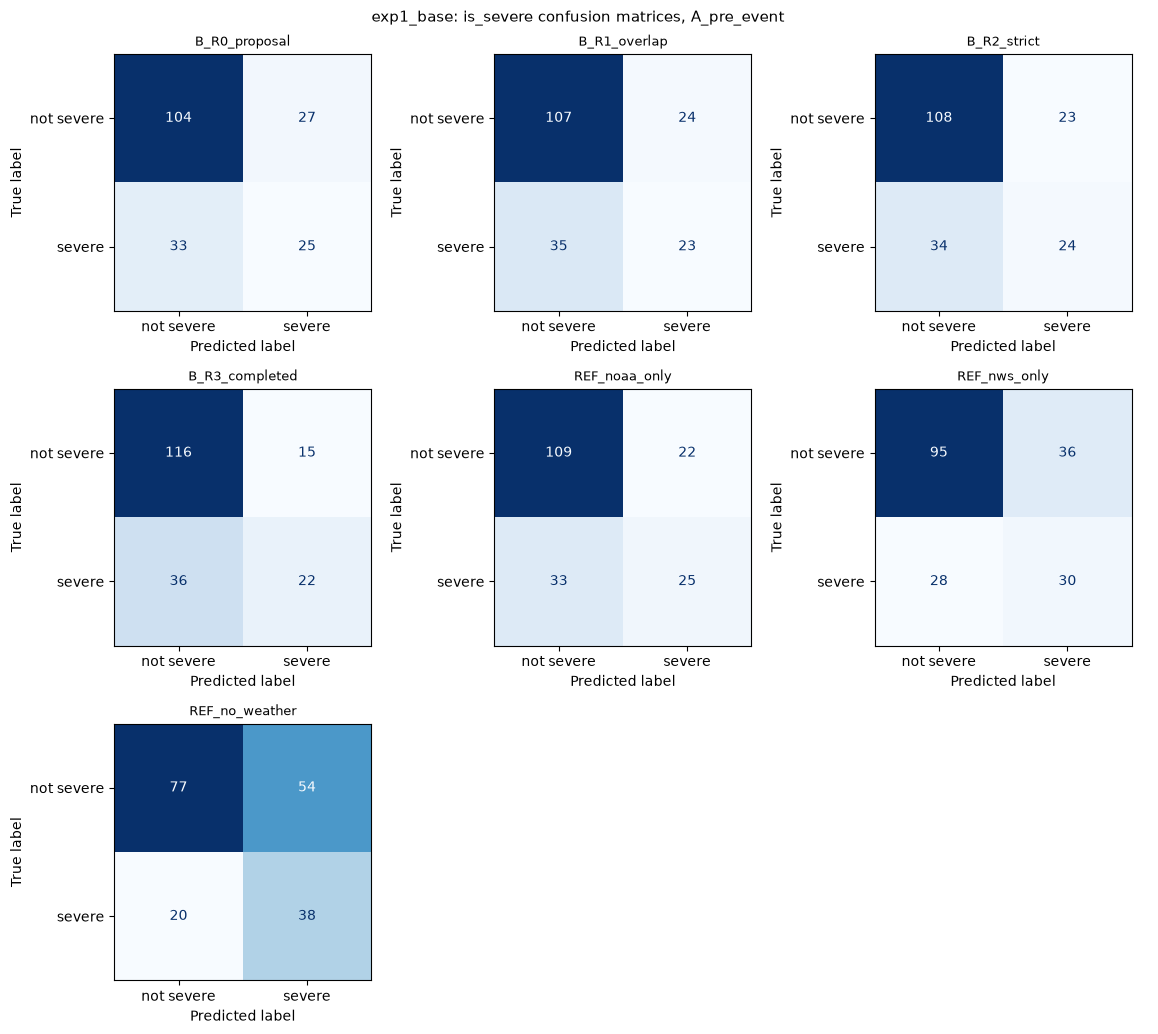

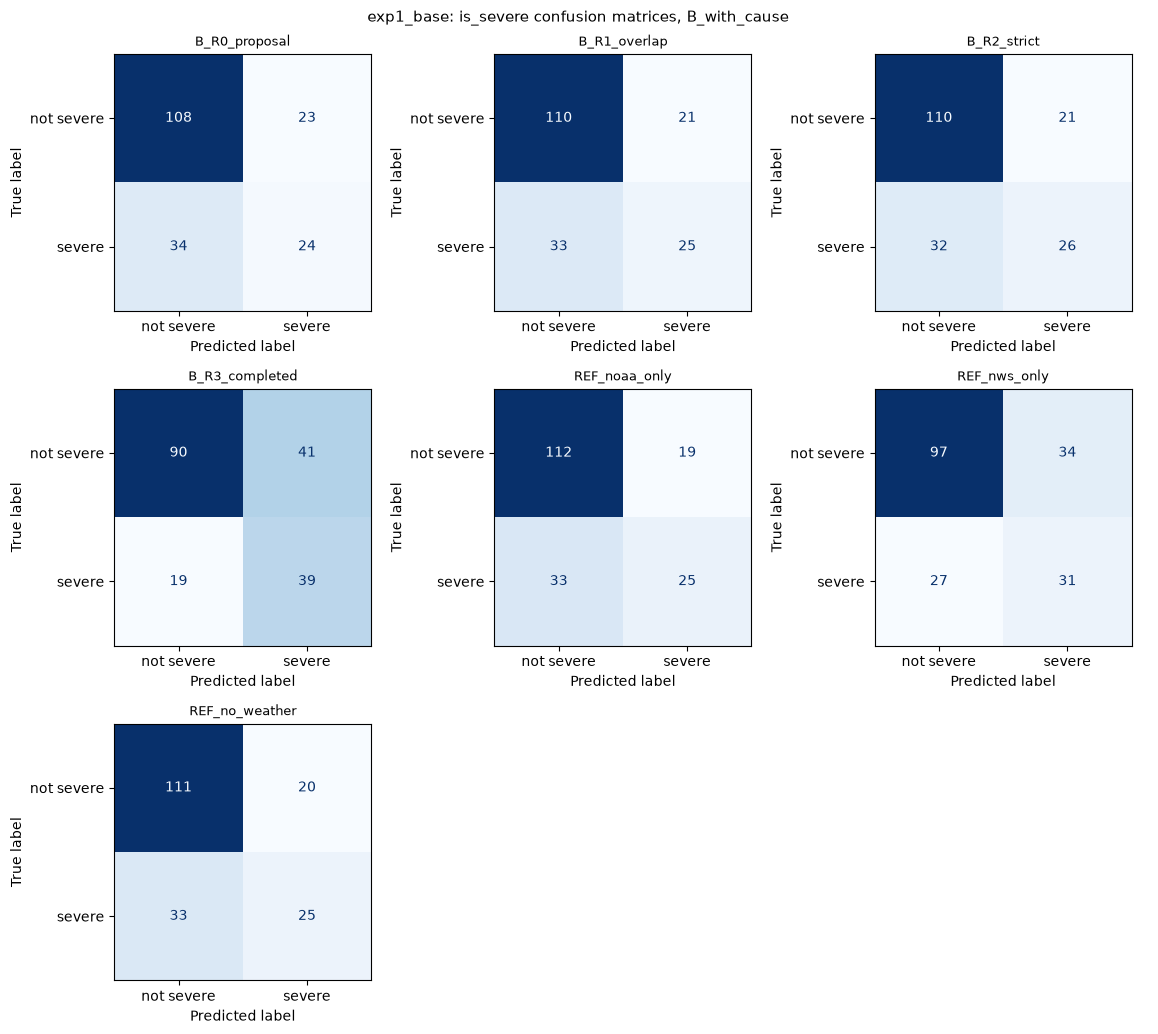

In [29]:
confusion_for(base_preds, "exp1_base")

## 9. Experiment 2: proposed model

Same rules and models, with the added data.

In [30]:
prop_preds, prop_reg, prop_clf = run_experiment(PROPOSED_RUNS, "proposed")
show_results(prop_reg, prop_clf, "exp2_proposed")

  proposed | A_pre_event | P_R0_proposal: 126 numeric features (34s)


  proposed | A_pre_event | P_R1_overlap: 126 numeric features (29s)


  proposed | A_pre_event | P_R2_strict: 126 numeric features (31s)


  proposed | A_pre_event | P_R3_completed: 126 numeric features (30s)


  proposed | B_with_cause | P_R0_proposal: 131 numeric features (31s)


  proposed | B_with_cause | P_R1_overlap: 131 numeric features (29s)


... (4 outputs left out)

Regression: duration (log scale)


,scenario,run,n_test,RMSE,R2,MAE,Spearman
0,A_pre_event,P_R0_proposal,964,2.104,0.059,1.657,0.288
1,A_pre_event,P_R1_overlap,964,2.079,0.080,1.644,0.309
2,A_pre_event,P_R2_strict,964,2.077,0.083,1.638,0.315
3,A_pre_event,P_R3_completed,964,2.114,0.049,1.669,0.289
4,B_with_cause,P_R0_proposal,964,2.076,0.083,1.640,0.265
5,B_with_cause,P_R1_overlap,964,2.057,0.100,1.624,0.283
6,B_with_cause,P_R2_strict,964,2.038,0.116,1.606,0.299
7,B_with_cause,P_R3_completed,964,2.054,0.102,1.615,0.287


Classification: is_severe


,scenario,run,n_test,accuracy,balanced_accuracy,precision,recall,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,A_pre_event,P_R0_proposal,189,0.667,0.620,0.460,0.500,0.479,0.718,0.597,97,34,29,29
1,A_pre_event,P_R1_overlap,189,0.651,0.623,0.444,0.552,0.492,0.723,0.608,91,40,26,32
2,A_pre_event,P_R2_strict,189,0.698,0.653,0.508,0.534,0.521,0.731,0.622,101,30,27,31
3,A_pre_event,P_R3_completed,189,0.741,0.630,0.645,0.345,0.449,0.741,0.623,120,11,38,20
4,B_with_cause,P_R0_proposal,189,0.704,0.618,0.523,0.397,0.451,0.760,0.607,110,21,35,23
5,B_with_cause,P_R1_overlap,189,0.698,0.634,0.509,0.466,0.486,0.757,0.604,105,26,31,27
6,B_with_cause,P_R2_strict,189,0.714,0.645,0.540,0.466,0.500,0.765,0.629,108,23,31,27
7,B_with_cause,P_R3_completed,189,0.709,0.684,0.522,0.621,0.567,0.777,0.627,98,33,22,36


### 9.1 Confusion matrices: proposed model

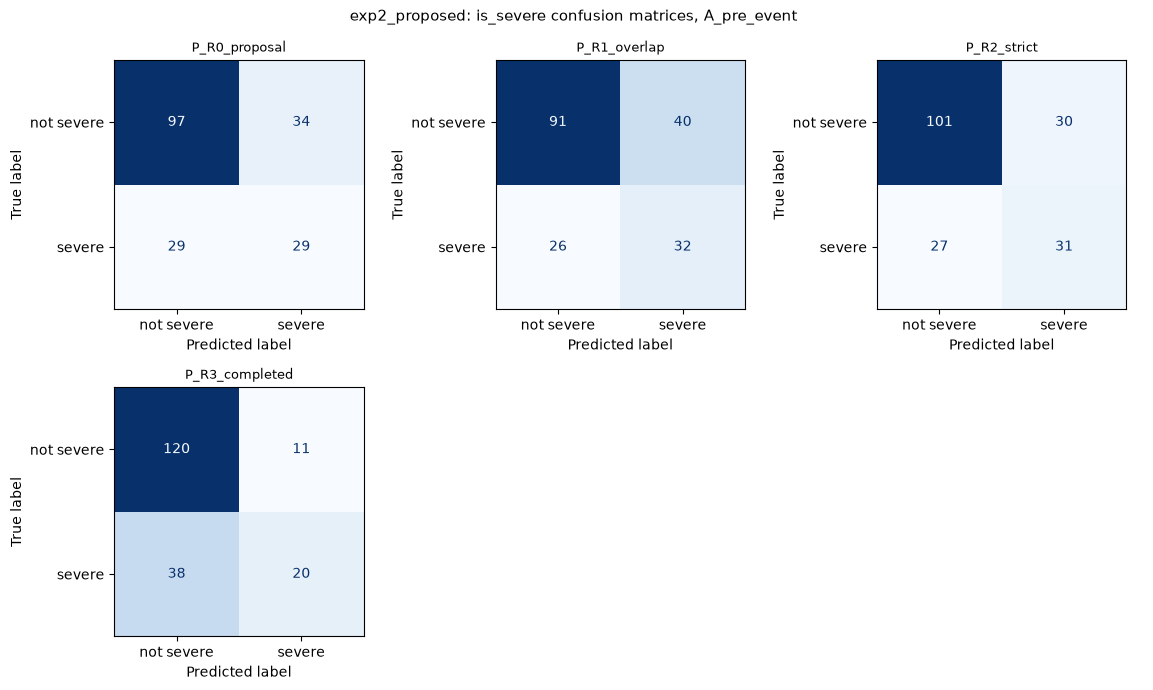

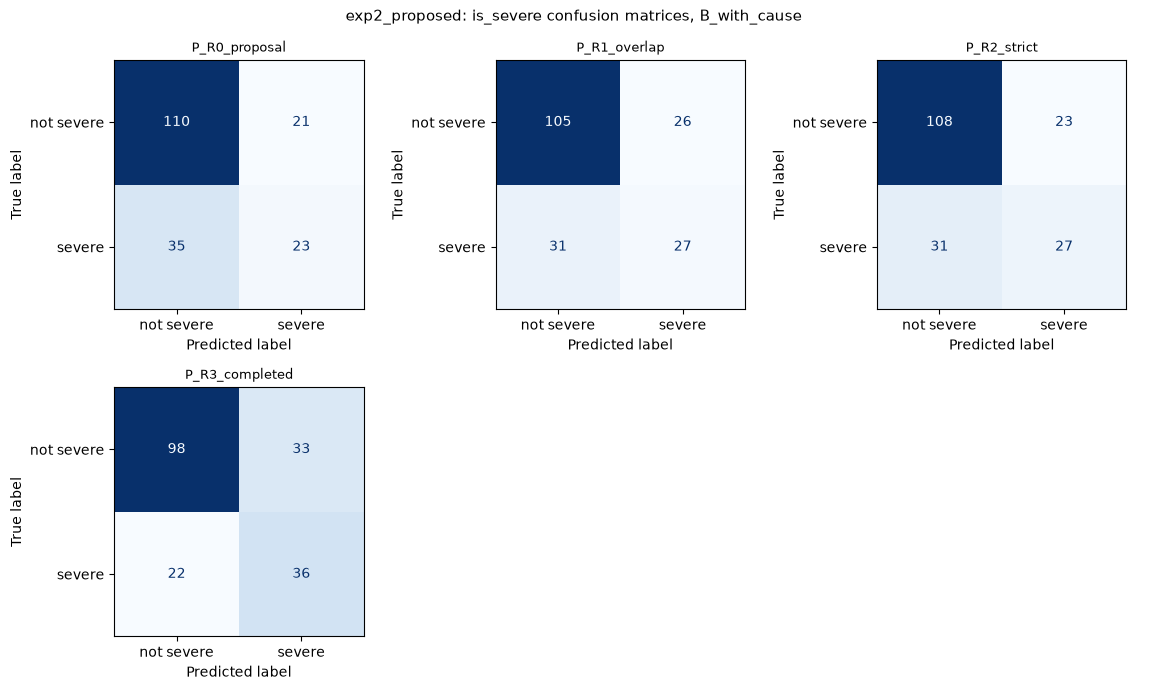

In [31]:
confusion_for(prop_preds, "exp2_proposed")

## 10. Base vs. proposed: does the added data help?

Each proposed run is paired with the base run that uses the same storm rule. The change is **proposed − base**:
- positive is better for R², Spearman, F1, ROC-AUC, PR-AUC and balanced accuracy;
- **negative** is better for RMSE and MAE.

In [32]:
pair = {p: b for p, b in zip(PROPOSED_RUNS, BASE_RUNS)}
r = prop_reg.assign(base_run=prop_reg["run"].map(pair)).merge(
    base_reg, left_on=["target", "scenario", "base_run"], right_on=["target", "scenario", "run"],
    suffixes=("_proposed", "_base"))
reg_cmp = r[["target", "scenario", "run_base", "run_proposed"]].copy()
for m in ["RMSE", "R2", "MAE", "Spearman"]:
    reg_cmp[f"{m}_base"], reg_cmp[f"{m}_proposed"] = r[f"{m}_base"], r[f"{m}_proposed"]
    reg_cmp[f"{m}_change"] = r[f"{m}_proposed"] - r[f"{m}_base"]
c = prop_clf.assign(base_run=prop_clf["run"].map(pair)).merge(
    base_clf, left_on=["scenario", "base_run"], right_on=["scenario", "run"], suffixes=("_proposed", "_base"))
clf_cmp = c[["scenario", "run_base", "run_proposed"]].copy()
for m in ["precision", "recall", "F1", "ROC_AUC", "PR_AUC", "balanced_accuracy", "accuracy"]:
    clf_cmp[f"{m}_base"], clf_cmp[f"{m}_proposed"] = c[f"{m}_base"], c[f"{m}_proposed"]
    clf_cmp[f"{m}_change"] = c[f"{m}_proposed"] - c[f"{m}_base"]
reg_cmp.to_csv(os.path.join(OUT_DIR, "comparison_regression.csv"), index=False)
clf_cmp.to_csv(os.path.join(OUT_DIR, "comparison_is_severe.csv"), index=False)
print("Regression: change = proposed - base")
display(reg_cmp[["target", "scenario", "run_base", "R2_base", "R2_proposed", "R2_change",
                 "RMSE_change", "MAE_change", "Spearman_change"]].round(3).reset_index(drop=True))
print("is_severe: change = proposed - base")
display(clf_cmp[["scenario", "run_base", "ROC_AUC_base", "ROC_AUC_proposed", "ROC_AUC_change", "PR_AUC_change",
                 "F1_change", "precision_change", "recall_change", "balanced_accuracy_change"]].round(3).reset_index(drop=True))

Regression: change = proposed - base


,target,scenario,run_base,R2_base,R2_proposed,R2_change,RMSE_change,MAE_change,Spearman_change
0,customers,A_pre_event,B_R0_proposal,0.348,0.361,0.013,-0.017,-0.008,0.008
1,duration,A_pre_event,B_R0_proposal,0.064,0.059,-0.005,0.006,0.003,-0.004
2,customers,A_pre_event,B_R1_overlap,0.401,0.406,0.005,-0.007,-0.002,0.003
3,duration,A_pre_event,B_R1_overlap,0.084,0.080,-0.004,0.004,0.004,-0.002
4,customers,A_pre_event,B_R2_strict,0.421,0.427,0.006,-0.008,0.001,0.001
5,duration,A_pre_event,B_R2_strict,0.089,0.083,-0.007,0.007,0.004,-0.001
6,customers,A_pre_event,B_R3_completed,0.378,0.387,0.009,-0.012,-0.008,0.007
7,duration,A_pre_event,B_R3_completed,0.060,0.049,-0.010,0.011,0.008,-0.006
8,customers,B_with_cause,B_R0_proposal,0.482,0.492,0.010,-0.015,0.003,0.004
9,duration,B_with_cause,B_R0_proposal,0.079,0.083,0.004,-0.004,-0.002,-0.001


is_severe: change = proposed - base


,scenario,run_base,ROC_AUC_base,ROC_AUC_proposed,ROC_AUC_change,PR_AUC_change,F1_change,precision_change,recall_change,balanced_accuracy_change
0,A_pre_event,B_R0_proposal,0.722,0.718,-0.004,-0.006,0.025,-0.020,0.069,0.008
1,A_pre_event,B_R1_overlap,0.722,0.723,0.001,0.006,0.054,-0.045,0.155,0.017
2,A_pre_event,B_R2_strict,0.726,0.731,0.005,0.004,0.064,-0.002,0.121,0.034
3,A_pre_event,B_R3_completed,0.736,0.741,0.005,0.013,-0.014,0.051,-0.034,-0.002
4,B_with_cause,B_R0_proposal,0.763,0.760,-0.003,-0.011,-0.006,0.012,-0.017,-0.001
5,B_with_cause,B_R1_overlap,0.763,0.757,-0.006,-0.026,0.006,-0.034,0.034,-0.002
6,B_with_cause,B_R2_strict,0.768,0.765,-0.003,-0.010,0.005,-0.013,0.017,0.001
7,B_with_cause,B_R3_completed,0.775,0.777,0.002,-0.007,0.002,0.034,-0.052,0.005


## 11. Severe detection in detail (operational rule): base vs. proposed

The professor's feedback (W3) asked for useful baselines and a cost-sensitive view. This section uses the **operational (strict) rule** for both models.

| Group | Methods |
|---|---|
| Baselines | always not severe (majority class), always severe, random at the training rate (one draw) |
| Rules | storm active → severe; (scenario B) cause = severe weather → severe |
| Models | logistic regression; ensemble uncalibrated / Platt-calibrated; calibrated ensemble with a **cost-tuned threshold** (missed severe : false alarm = 1:1, 3:1, 5:1, tuned on training data) |

Expected cost per outage = (c × missed severe + false alarms) / n; lower is better.

In [33]:
def _cost_threshold(p, y, c):
    grid = np.linspace(0.01, 0.99, 99)
    cost = [c * ((y == 1) & (p < t)).sum() + ((y == 0) & (p >= t)).sum() for t in grid]
    return grid[int(np.argmin(cost))]


def severe_detection_eval(df, scen, opts):
    num, cat = feature_sets(df, scen, **opts)
    dev, test = df[df["outage_start"] < TEST_START], df[df["outage_start"] >= TEST_START]
    d_tr, d_te = task_rows(dev, "bin", None), task_rows(test, "bin", None)
    y_tr, y_te = make_labels("bin", None, dev, d_tr, d_te)
    oof = inner_oof("bin", num, cat, d_tr, y_tr)                     # training-only predictions
    preds, _ = fit_and_predict("bin", num, cat, d_tr, y_tr, d_te, inner=True)
    raw = preds["ensemble"]
    logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
    platt = LogisticRegression(C=1e6).fit(logit(oof)[:, None], y_tr)  # calibration on training OOF
    cal_tr = platt.predict_proba(logit(oof)[:, None])[:, 1]
    cal = platt.predict_proba(logit(raw)[:, None])[:, 1]
    rng = np.random.default_rng(SEED)
    m = {"baseline: always not severe": (np.zeros(len(y_te), int), None),
         "baseline: always severe": (np.ones(len(y_te), int), None),
         "baseline: random (one draw)": ((rng.random(len(y_te)) < y_tr.mean()).astype(int), None),
         "rule: storm active": ((d_te["noaa_has_storm"].values == 1).astype(int), None)}
    if "cause_reported" in cat:
        m["rule: cause = severe weather"] = ((d_te["cause_reported"].values == "severe weather").astype(int), None)
    m["logistic regression (0.5)"] = ((preds["linear"] >= 0.5).astype(int), preds["linear"])
    m["ensemble, uncalibrated (0.5)"] = ((raw >= 0.5).astype(int), raw)
    m["ensemble, calibrated (0.5)"] = ((cal >= 0.5).astype(int), cal)
    for c in COST_RATIOS:
        t = _cost_threshold(cal_tr, y_tr, c)
        m[f"ensemble, cost {c}:1 (t={t:.2f})"] = ((cal >= t).astype(int), cal)
    rows = []
    for name, (yhat, p) in m.items():
        cost = {f"cost_{c}to1": (c * ((y_te == 1) & (yhat == 0)).sum() + ((y_te == 0) & (yhat == 1)).sum()) / len(y_te)
                for c in COST_RATIOS}
        rows.append({"scenario": scen, "method": name, **classification_metrics(y_te, yhat, p), **cost})
    bins = np.clip((cal * 10).astype(int), 0, 9)
    rel = (pd.DataFrame({"bin": bins, "pred_calibrated": cal, "pred_raw": raw, "observed": y_te})
           .groupby("bin").agg(mean_pred_calibrated=("pred_calibrated", "mean"),
                               mean_pred_raw=("pred_raw", "mean"), observed_rate=("observed", "mean"))
           .reset_index())
    info_ = {"scenario": scen, "n_test": len(y_te), "test_severe_rate": y_te.mean(), "train_severe_rate": y_tr.mean()}
    return pd.DataFrame(rows), y_te, m, rel, info_


OPERATIONAL = {"base": [k for k in BASE_RUNS if "strict" in k][0],
               "proposed": [k for k in PROPOSED_RUNS if "strict" in k][0]}
sev_tables, sev_preds, sev_rel, sev_info = [], {}, {}, []
for model_name, run in OPERATIONAL.items():
    tab, opts = {**BASE_RUNS, **PROPOSED_RUNS}[run]
    for scen in SCENARIOS:
        t, y_te, m, rel_, inf = severe_detection_eval(tables[tab], scen, opts)
        sev_tables.append(t.assign(model=model_name, run=run))
        sev_preds[(model_name, scen)] = (y_te, m)
        sev_rel[(model_name, scen)] = rel_
        sev_info.append({"model": model_name, **inf})
sev = pd.concat(sev_tables, ignore_index=True)
sev.to_csv(os.path.join(OUT_DIR, "severe_detection.csv"), index=False)
display(pd.DataFrame(sev_info).round(3))
display(sev[["model", "scenario", "method", "precision", "recall", "F1", "ROC_AUC", "PR_AUC",
             "balanced_accuracy", "accuracy", "cost_3to1", "cost_5to1"]].round(3))

,model,scenario,n_test,test_severe_rate,train_severe_rate
0,base,A_pre_event,189,0.307,0.5
1,base,B_with_cause,189,0.307,0.5
2,proposed,A_pre_event,189,0.307,0.5
3,proposed,B_with_cause,189,0.307,0.5


,model,scenario,method,precision,recall,F1,ROC_AUC,PR_AUC,balanced_accuracy,accuracy,cost_3to1,cost_5to1
0,base,A_pre_event,baseline: always not severe,0.000,0.000,0.000,NaN,NaN,0.500,0.693,0.921,1.534
1,base,A_pre_event,baseline: always severe,0.307,1.000,0.470,NaN,NaN,0.500,0.307,0.693,0.693
2,base,A_pre_event,baseline: random (one draw),0.381,0.638,0.477,NaN,NaN,0.590,0.571,0.651,0.873
3,base,A_pre_event,rule: storm active,0.318,0.862,0.465,NaN,NaN,0.523,0.392,0.693,0.778
4,base,A_pre_event,logistic regression (0.5),0.607,0.586,0.596,0.771,0.689,0.709,0.757,0.497,0.751
5,base,A_pre_event,"ensemble, uncalibrated (0.5)",0.459,0.483,0.471,0.726,0.618,0.615,0.667,0.651,0.968
6,base,A_pre_event,"ensemble, calibrated (0.5)",0.467,0.483,0.475,0.726,0.618,0.619,0.672,0.646,0.963
7,base,A_pre_event,"ensemble, cost 1:1 (t=0.53)",0.521,0.431,0.472,0.726,0.618,0.628,0.704,0.646,0.995
8,base,A_pre_event,"ensemble, cost 3:1 (t=0.21)",0.382,0.948,0.545,0.726,0.618,0.634,0.513,0.519,0.550
9,base,A_pre_event,"ensemble, cost 5:1 (t=0.18)",0.367,0.948,0.529,0.726,0.618,0.612,0.481,0.550,0.582


### 11.1 Confusion matrices: severe detection

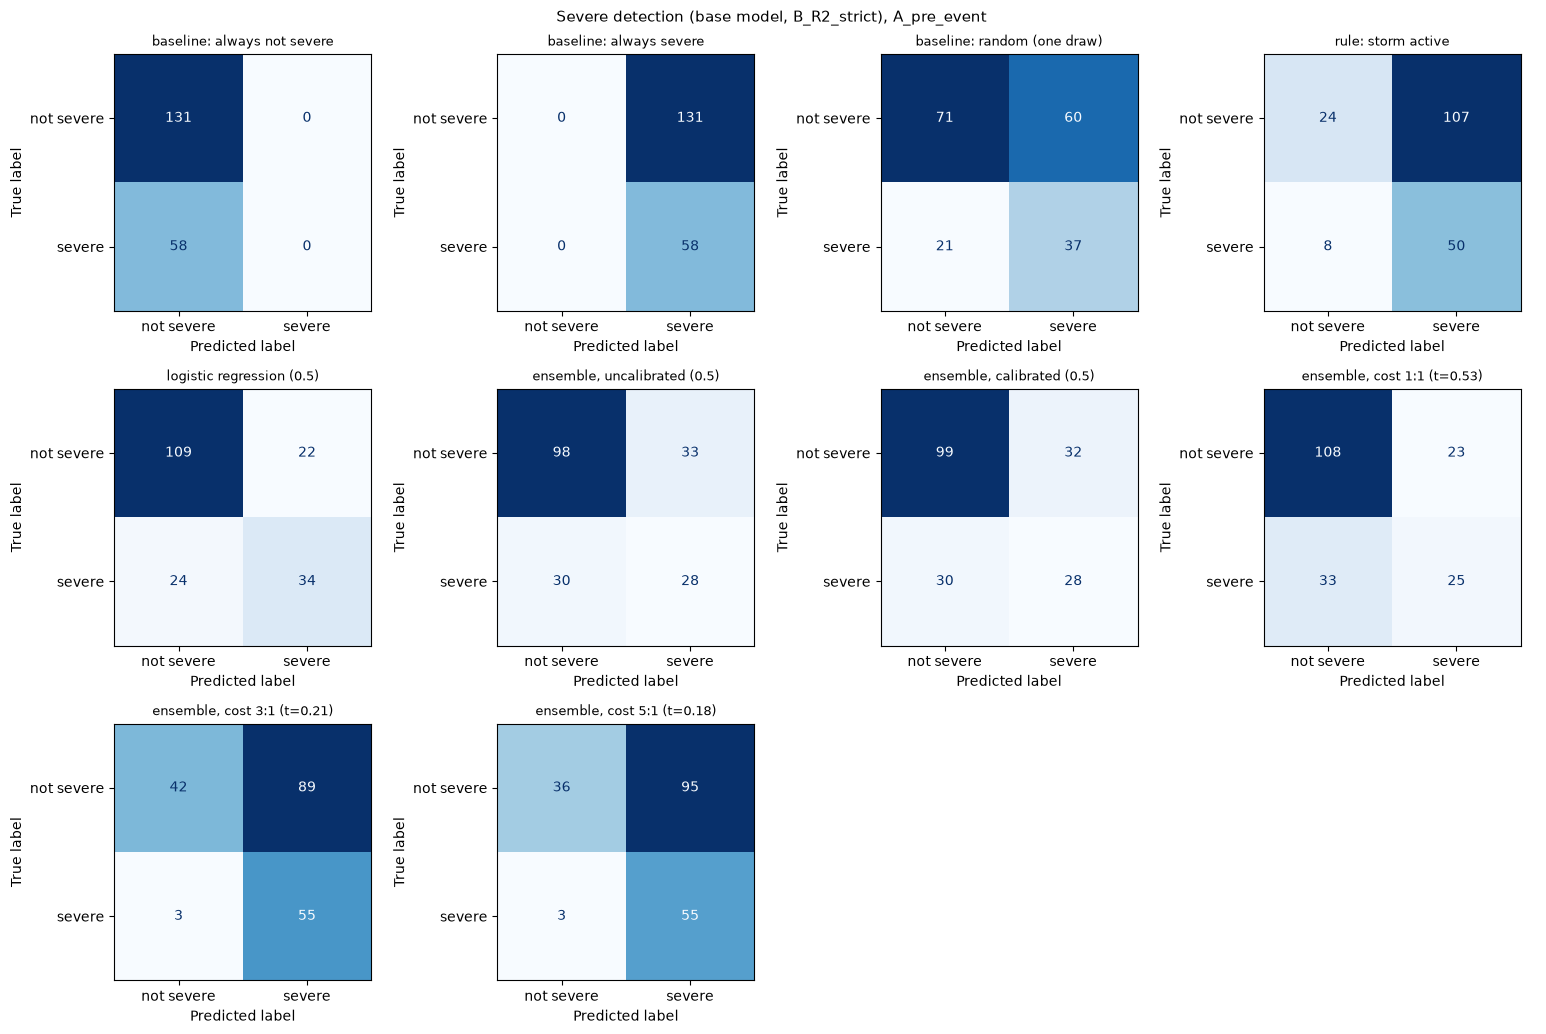

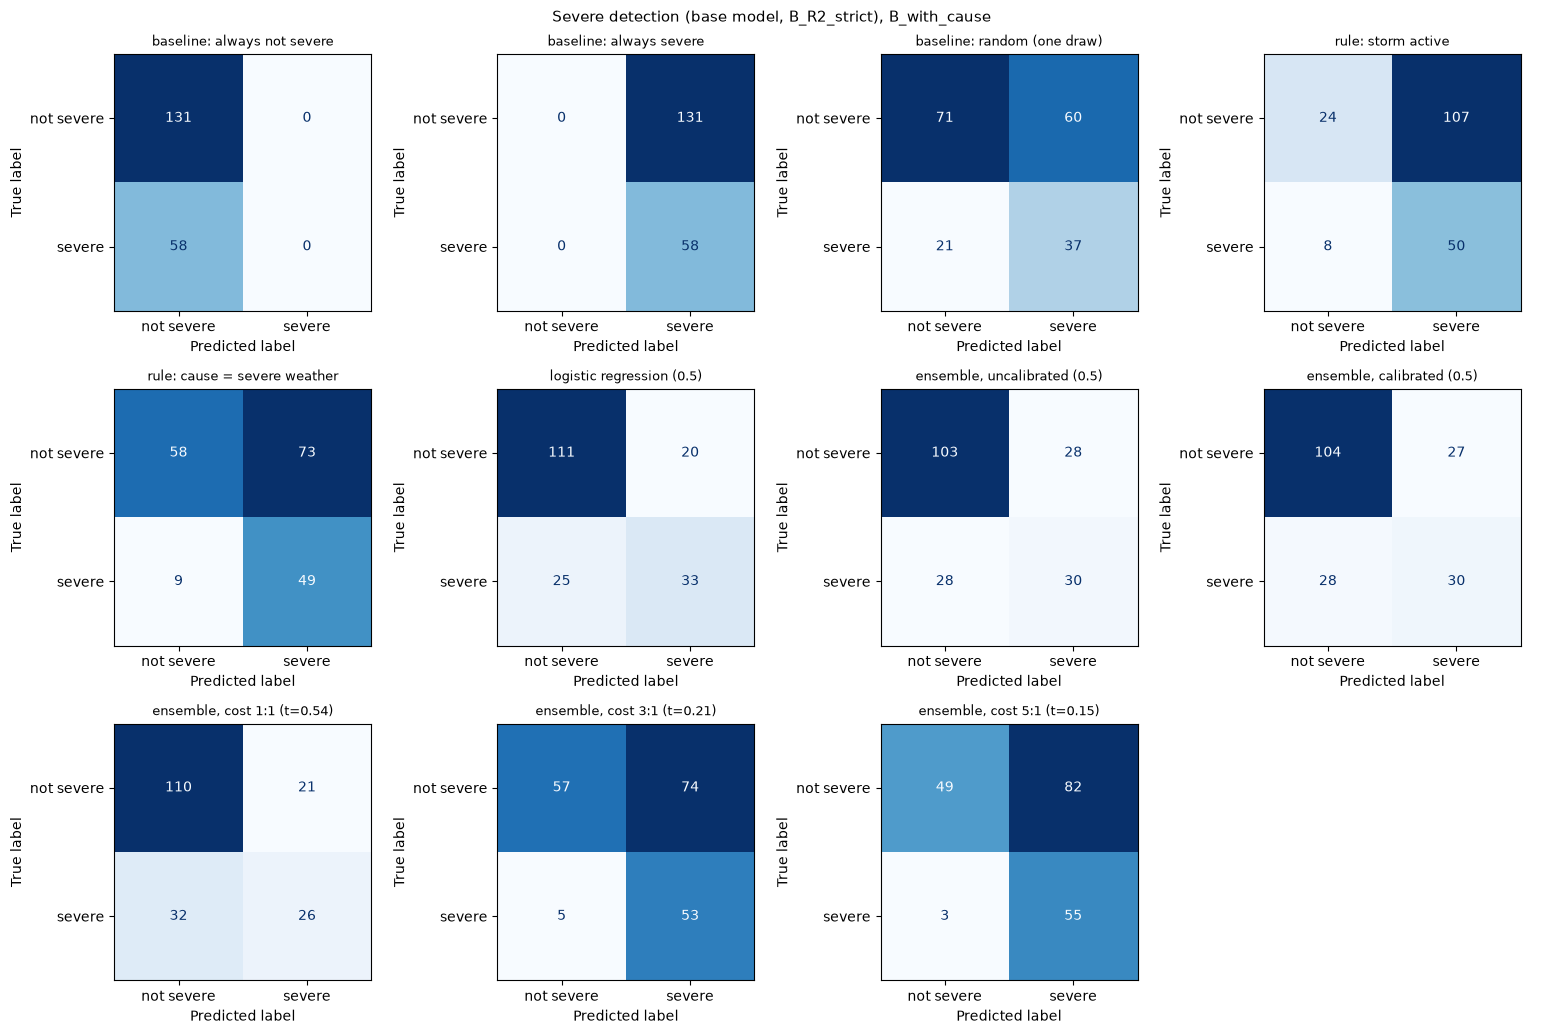

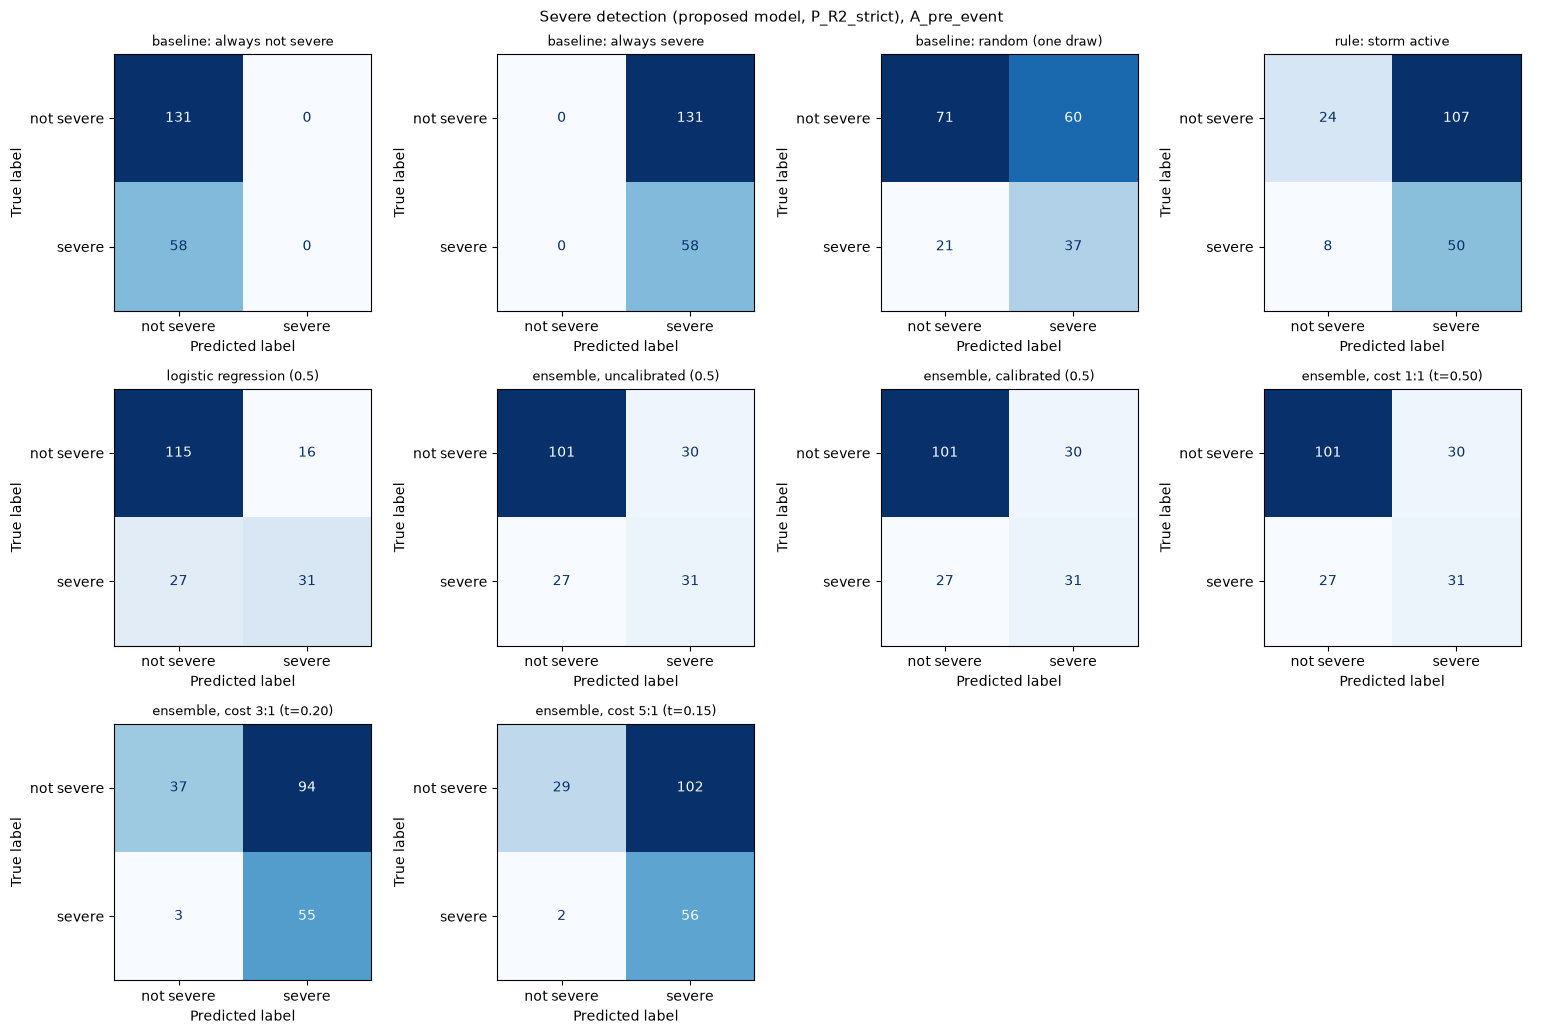

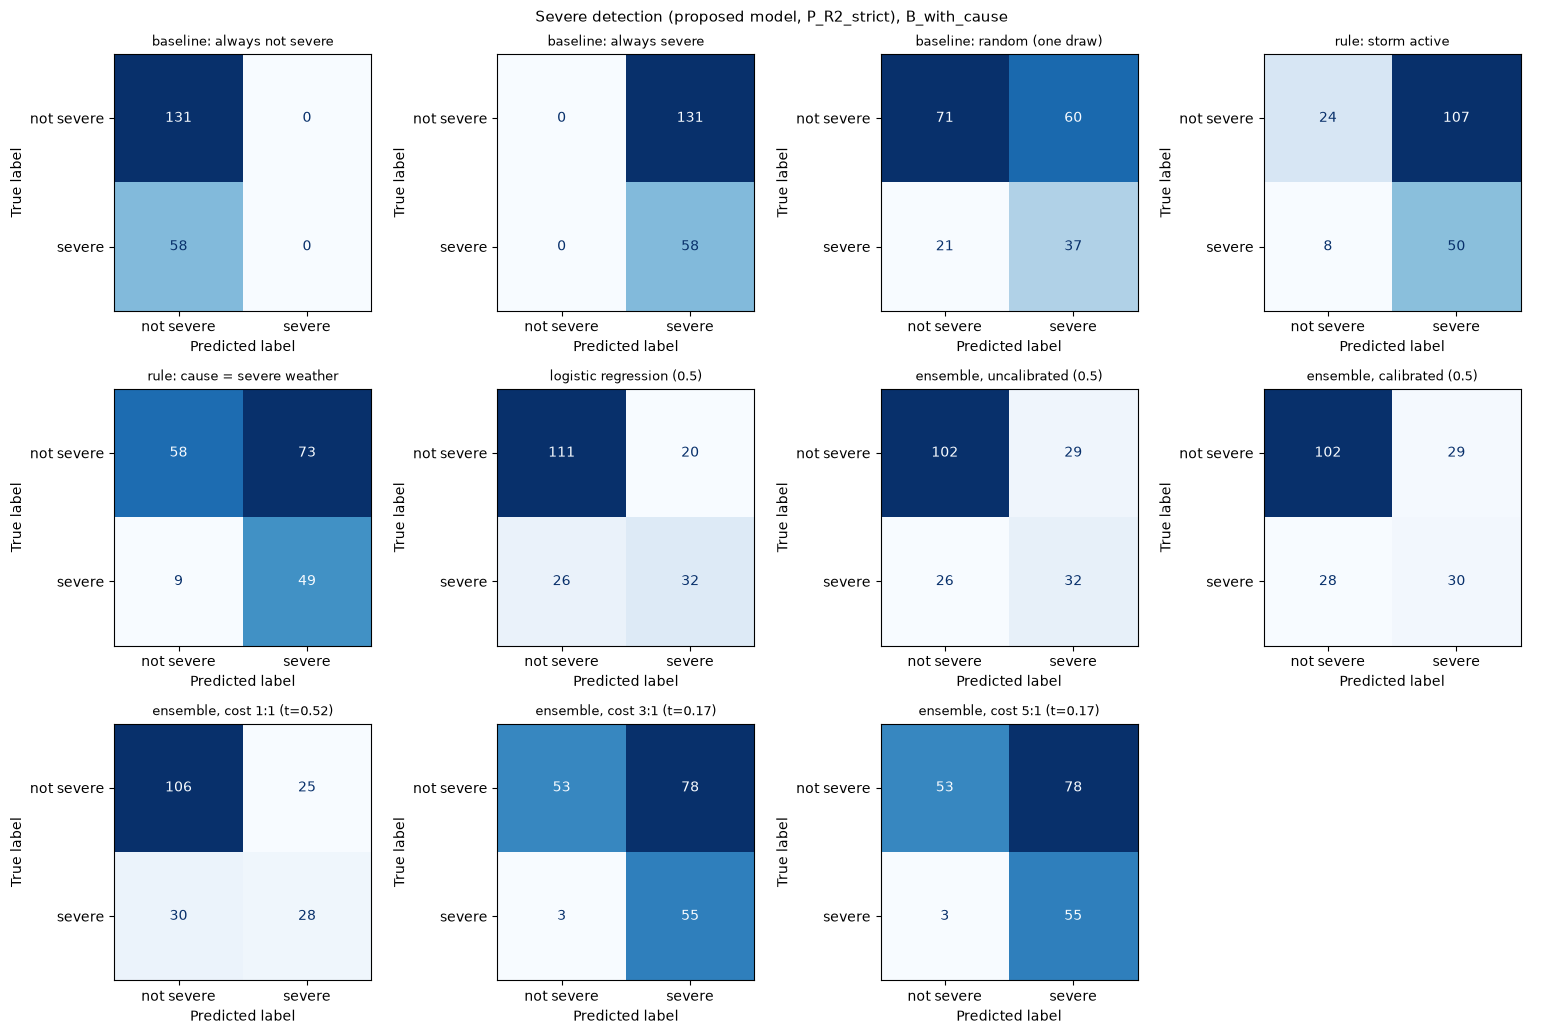

In [34]:
for (model_name, scen), (y_te, m) in sev_preds.items():
    items = [(name, y_te, yhat) for name, (yhat, p) in m.items()]
    plot_confusion_grid(items, f"Severe detection ({model_name} model, {OPERATIONAL[model_name]}), {scen}",
                        os.path.join(OUT_DIR, f"severe_confusion_{model_name}_{scen}.png"), ncols=4)

### 11.2 Reliability (calibration) plot

When the model says "x% chance of severe", how often was it really severe? Points on the dashed line are honest probabilities.

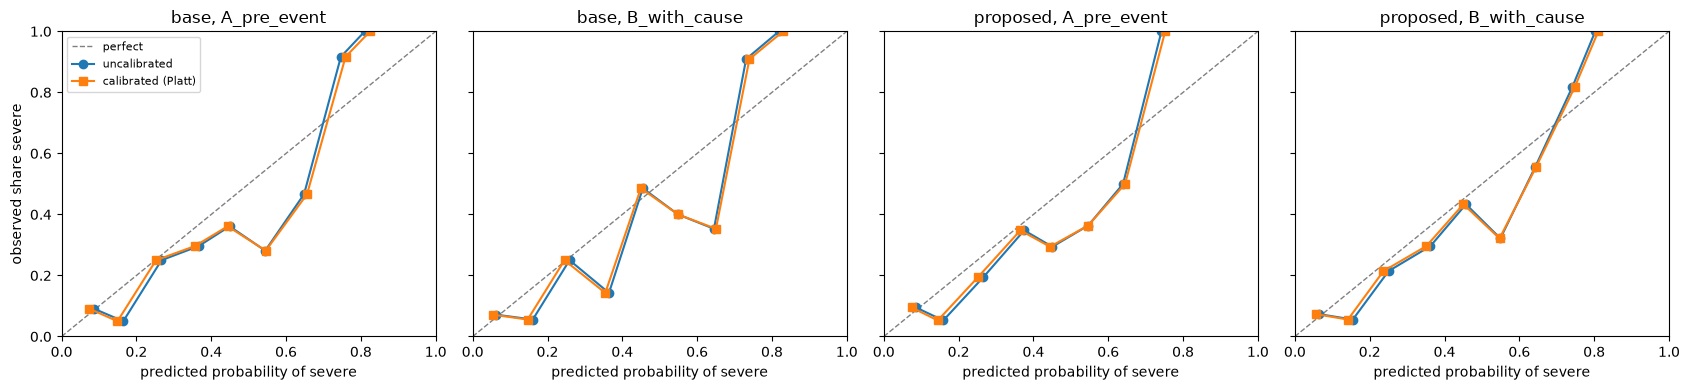

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, ((model_name, scen), g) in zip(axes, sev_rel.items()):
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="perfect")
    ax.plot(g["mean_pred_raw"], g["observed_rate"], "o-", label="uncalibrated")
    ax.plot(g["mean_pred_calibrated"], g["observed_rate"], "s-", label="calibrated (Platt)")
    ax.set(title=f"{model_name}, {scen}", xlabel="predicted probability of severe", xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("observed share severe")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "reliability.png"), dpi=130)
plt.show()

## 12. Summary

The results are in the tables above and in `progress_stage2/results_outage_extended_noaa_nws_newgrid/` (test period 2022–2024).
- **Section 8** gives every metric for the base model (outage + NOAA + NWS warnings). The references show what NWS warnings add (`REF_noaa_only`) and how well real-time warnings do on their own (`REF_nws_only`, the most defensible weather input for the operational claim, W1).
- **Section 9** does the same for the proposed model (+ EIA-861 / FERC Form 1).
- **Section 10** shows what the new grid data changes for each storm rule.
- **Section 11** compares severe-detection methods, including baselines and cost-sensitive thresholds.

Note: NWS features are missing for outages before 2006 (the archive is complete only from Nov 2005); the test period 2022–2024 is fully covered.